# Synthetic Medical Image Generation on the PMOS Dataset via Transfer-Learned StyleGAN2-ADA

**Pipeline:** Pretrained StyleGAN2-ADA (FFHQ-256, NVlabs official PyTorch implementation) &rarr; fine-tuned with adaptive discriminator augmentation (ADA) on the PMOS medical image dataset &rarr; evaluated with FID / KID &rarr; best checkpoint exported for synthetic dataset generation.

This notebook is designed to be:
- **Reproducible** — every stage is a self-contained, numbered section with explanatory markdown.
- **Small-dataset friendly** — transfer learning + ADA augmentation instead of training from scratch (~700 images is far too small for from-scratch GAN training).
- **Kaggle T4 friendly** — a wall-clock time budget keeps the whole run inside a single Kaggle GPU session (~6-7 hours).
- **Modular** — helper functions are defined once and reused; no giant monolithic cells.

> **Design decision (per project scope):** the source dataset contains two sub-folders, `PMOS` and `NON PMOS`. Per the project requirements, both are **combined into a single unconditional image pool** (~732 images) — the GAN learns one general image distribution rather than being class-conditioned. If class-conditional generation is needed later, Section 8 notes how to switch to a labeled dataset.

---
## Table of Contents
1. Install Dependencies
2. Import Libraries
3. GPU Information
4. Dataset Loading
5. Dataset Analysis (EDA)
6. Dataset Preparation
7. Resize Images (256&times;256)
8. Convert Dataset to StyleGAN Format
9. Download Pretrained StyleGAN2-ADA
10. Configure Training
11. Start Fine-tuning (time-boxed)
12. Resume Training (contingency)
13. Generate Evaluation Images per Checkpoint
14. Calculate FID
15. Calculate KID (+ optional LPIPS diversity)
16. Save Best Model
17. Export Final Synthetic Dataset
18. Publication Figures & Save Results
- How to Run
---


## 0. Project Folder Setup

All outputs are organized under `/kaggle/working/` so the whole run is self-contained and easy to download at the end.

| Folder | Contents |
|---|---|
| `data/` | Resized 256&times;256 dataset + StyleGAN-format zip |
| `pretrained/` | Downloaded pretrained source network |
| `training-runs/` | StyleGAN2-ADA run directories, logs, checkpoints |
| `metrics/` | Per-checkpoint evaluation images + FID/KID tables |
| `generated/` | Final large-scale synthetic image export |
| `figures/` | Publication-ready figures (PNG + PDF) |
| `results/` | Best model, summary JSON, zipped deliverables |


In [10]:
import os

WORK_DIR = "/kaggle/working"   # writable — সব output এখানে যাবে

PATHS = {
    "data": f"{WORK_DIR}/data",
    "processed": f"{WORK_DIR}/data/processed_256",
    "pretrained": f"{WORK_DIR}/pretrained",
    "runs": f"{WORK_DIR}/training-runs",
    "metrics": f"{WORK_DIR}/metrics",
    "generated": f"{WORK_DIR}/generated",
    "figures": f"{WORK_DIR}/figures",
    "results": f"{WORK_DIR}/results",
    "repo": f"{WORK_DIR}/stylegan2-ada-pytorch",
}

for p in PATHS.values():
    os.makedirs(p, exist_ok=True)

print("Project folders ready:")
for k, v in PATHS.items():
    print(f"  {k:12s} -> {v}")

Project folders ready:
  data         -> /kaggle/working/data
  processed    -> /kaggle/working/data/processed_256
  pretrained   -> /kaggle/working/pretrained
  runs         -> /kaggle/working/training-runs
  metrics      -> /kaggle/working/metrics
  generated    -> /kaggle/working/generated
  figures      -> /kaggle/working/figures
  results      -> /kaggle/working/results
  repo         -> /kaggle/working/stylegan2-ada-pytorch


## 1. Install Dependencies

Kaggle's Python/GPU image already ships PyTorch, torchvision, NumPy, Pandas, Matplotlib, Seaborn, OpenCV and Pillow, so we only install the packages that are **missing**:

- `ninja` &mdash; required to JIT-compile the custom CUDA ops (`upfirdn2d`, `bias_act`) used by the official StyleGAN2-ADA implementation.
- `torchmetrics` + `torch-fidelity` &mdash; give a well-tested, reproducible FID / KID implementation (InceptionV3 features), avoiding the well-known pitfalls of hand-rolled FID code.
- `imageio` / `imageio-ffmpeg` &mdash; used by the official repo's utilities.
- `lpips` &mdash; optional perceptual-diversity metric (Section 15).

**Note:** Kaggle's "Internet" toggle must be **ON** (Settings &rarr; Internet) since this notebook clones a GitHub repo and downloads a pretrained checkpoint.


In [11]:
%%capture install_log
!pip install -q ninja imageio "imageio-ffmpeg==0.4.9" torchmetrics torch-fidelity lpips requests tqdm


In [12]:
# Surface the install log only if something went wrong (keeps the notebook clean)
if "ERROR" in install_log.stdout or "error" in install_log.stdout.lower():
    print(install_log.stdout[-3000:])
else:
    print("Dependencies installed successfully.")


Dependencies installed successfully.


## 2. Import Libraries

Centralizing all imports in one cell keeps the rest of the notebook clean and makes dependency requirements explicit at a glance.


In [13]:
import os
import sys
import json
import time
import glob
import shutil
import random
import hashlib
import subprocess
import warnings
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__}")
print(f"Seed         : {SEED}")


Python       : 3.12.13
PyTorch      : 2.10.0+cu128
Seed         : 42


## 3. GPU Information

Confirms a CUDA GPU is attached (this pipeline assumes a Kaggle **T4** — either single or dual) and reports memory / driver details. StyleGAN2-ADA training will not run in a reasonable time on CPU, so we fail fast with a clear message if no GPU is found.


In [14]:
assert torch.cuda.is_available(), (
    "No CUDA GPU detected. In Kaggle: Settings -> Accelerator -> GPU T4 x1 (or x2), "
    "then Restart & Run All."
)

N_GPUS = torch.cuda.device_count()
DEVICE = torch.device("cuda")

for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"GPU {i}: {props.name} | {props.total_memory / 1e9:.1f} GB | "
          f"CUDA capability {props.major}.{props.minor}")

print(f"\nNumber of GPUs visible to PyTorch: {N_GPUS}")
print("\n--- nvidia-smi ---")
subprocess.run(["nvidia-smi"])


GPU 0: Tesla T4 | 15.6 GB | CUDA capability 7.5
GPU 1: Tesla T4 | 15.6 GB | CUDA capability 7.5

Number of GPUs visible to PyTorch: 2

--- nvidia-smi ---
Sat Aug 29 07:06:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       3MiB /  15360MiB |      0%  

CompletedProcess(args=['nvidia-smi'], returncode=0)

## 4. Dataset Loading

Set `DATASET_ROOT` manually below if you know the exact path to the extracted **PMOSCleaned** Kaggle dataset. If left as `None`, the notebook auto-detects it by scanning `/kaggle/input` for a directory that contains a `PMOS` sub-folder — this makes the notebook portable across different dataset-mount names without edits.

Per the project scope, images from both `PMOS` and `NON PMOS` sub-folders are pooled into **one combined, unconditional** image set for GAN training.


In [15]:
# ----------------------------------------------------------------
# MANUAL OVERRIDE (edit this if auto-detection fails)
# Example: DATASET_ROOT = "/kaggle/input/pmoscleaned/PMOSCleaned"
# ----------------------------------------------------------------
DATASET_ROOT = "/kaggle/input/datasets/shuvosingh/lus-cnn-hybrid/LUS Images for Automated AI-based Lung Disease Classification" 

IMG_EXTS = (".jpg", ".jpeg", ".png")


def find_dataset_root(search_base="/kaggle/input", marker_dirname="PMOS"):
    """Auto-detect the dataset root by locating a directory that contains
    a sub-folder named `marker_dirname` (case-insensitive)."""
    for dirpath, dirnames, _ in os.walk(search_base):
        for d in dirnames:
            if d.strip().lower() == marker_dirname.lower():
                return dirpath
    return None


if DATASET_ROOT is None:
    DATASET_ROOT = find_dataset_root()

assert DATASET_ROOT is not None and os.path.isdir(DATASET_ROOT), (
    "Could not locate the PMOSCleaned dataset. Add it via 'Add Input' in Kaggle, "
    "or set DATASET_ROOT manually above."
)

print(f"Dataset root: {DATASET_ROOT}")
print("Contents    :", os.listdir(DATASET_ROOT))


Dataset root: /kaggle/input/datasets/shuvosingh/lus-cnn-hybrid/LUS Images for Automated AI-based Lung Disease Classification
Contents    : ['other', 'healthy', 'covid']


In [16]:
def collect_images(dataset_root):
    """Walk the dataset root and collect (path, class_label) for every image,
    regardless of exact sub-folder naming/casing."""
    records = []
    for dirpath, _, filenames in os.walk(dataset_root):
        class_name = os.path.basename(dirpath).strip()
        if class_name == os.path.basename(dataset_root.rstrip("/")):
            continue
        for fn in filenames:
            if fn.lower().endswith(IMG_EXTS):
                records.append({"path": os.path.join(dirpath, fn), "class": class_name})
    return pd.DataFrame(records)


df_images = collect_images(DATASET_ROOT)
assert len(df_images) > 0, "No images found under the dataset root — check DATASET_ROOT."

print(f"Total images found: {len(df_images)}")
print(df_images["class"].value_counts())


Total images found: 1062
class
other      362
healthy    362
covid      338
Name: count, dtype: int64


## 5. Dataset Analysis (EDA)

A focused, non-redundant EDA — just enough to characterize the dataset for the paper's Methods section: class balance, resolution distribution, a visual sample grid, per-channel intensity distribution, and summary statistics. No unnecessary plots.


findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
findfont: Font family 'Comic Neue' not found.
findfont: Font family 'Comic Sans MS' not found.
findfont: Font family 'xkcd' not found.
findfont: Font family 'xkcd Script' not found.
fin

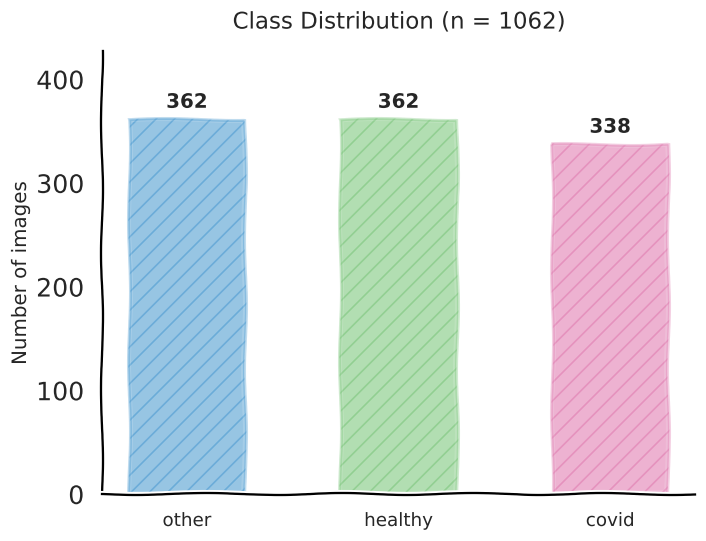

In [17]:
# --- 5.1 Class balance (hand-drawn style) -------------------------------
with plt.xkcd(scale=1, length=150, randomness=2):

    fig, ax = plt.subplots(figsize=(7, 5.5))

    counts = df_images["class"].value_counts()
    colors = ["#4C9BD1", "#7BC67B", "#E07BB0", "#F0B429"][:len(counts)]

    bars = ax.bar(counts.index, counts.values, color=colors, alpha=0.35,
                   edgecolor=colors, linewidth=2, hatch="//", width=0.55)

    for i, v in enumerate(counts.values):
        ax.text(i, v + max(counts.values) * 0.03, str(v),
                ha="center", fontweight="bold", fontsize=13)

    ax.set_ylabel("Number of images", fontsize=13)
    ax.set_xlabel("")
    ax.set_title(f"Class Distribution (n = {len(df_images)})", fontsize=15, pad=15)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_ylim(0, max(counts.values) * 1.18)

    # extra bottom margin + wrap/rotate long class names so nothing gets cut off
    ax.set_xticks(range(len(counts.index)))
    ax.set_xticklabels(counts.index, fontsize=12, rotation=0, ha="center")

    plt.subplots_adjust(bottom=0.22)
    plt.tight_layout(pad=2.0)
    plt.savefig(f"{PATHS['figures']}/eda_class_distribution.png",
                bbox_inches="tight", dpi=200)
    plt.show()

In [18]:
# --- 5.2 Resolution statistics (reads image headers only -> fast) ------
def get_size(path):
    try:
        with Image.open(path) as im:
            return im.size  # (width, height)
    except Exception:
        return (np.nan, np.nan)

sizes = [get_size(p) for p in tqdm(df_images["path"], desc="Reading image headers")]
df_images["width"] = [s[0] for s in sizes]
df_images["height"] = [s[1] for s in sizes]
df_images["aspect_ratio"] = df_images["width"] / df_images["height"]

print(df_images[["width", "height", "aspect_ratio"]].describe().round(2))


Reading image headers:   0%|          | 0/1062 [00:00<?, ?it/s]

        width   height  aspect_ratio
count  1062.0  1062.00       1062.00
mean    438.9   489.94          0.94
std      76.6   136.83          0.22
min     214.0   208.00          0.63
25%     405.0   351.00          0.79
50%     414.0   511.00          0.80
75%     513.0   640.00          1.06
max     688.0   763.00          1.73


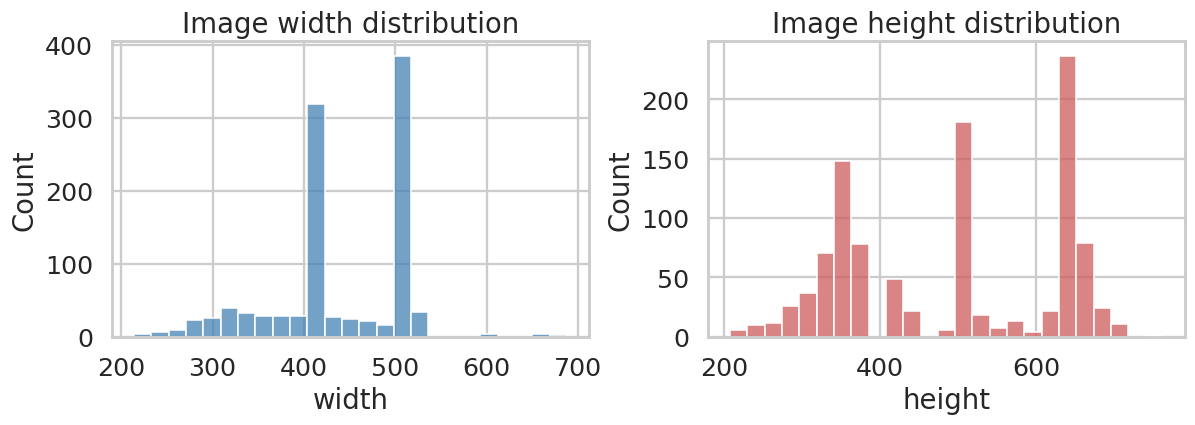

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_images["width"], bins=25, ax=axes[0], color="steelblue")
axes[0].set_title("Image width distribution")
sns.histplot(df_images["height"], bins=25, ax=axes[1], color="indianred")
axes[1].set_title("Image height distribution")
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/eda_resolution_distribution.png", bbox_inches="tight")
plt.show()


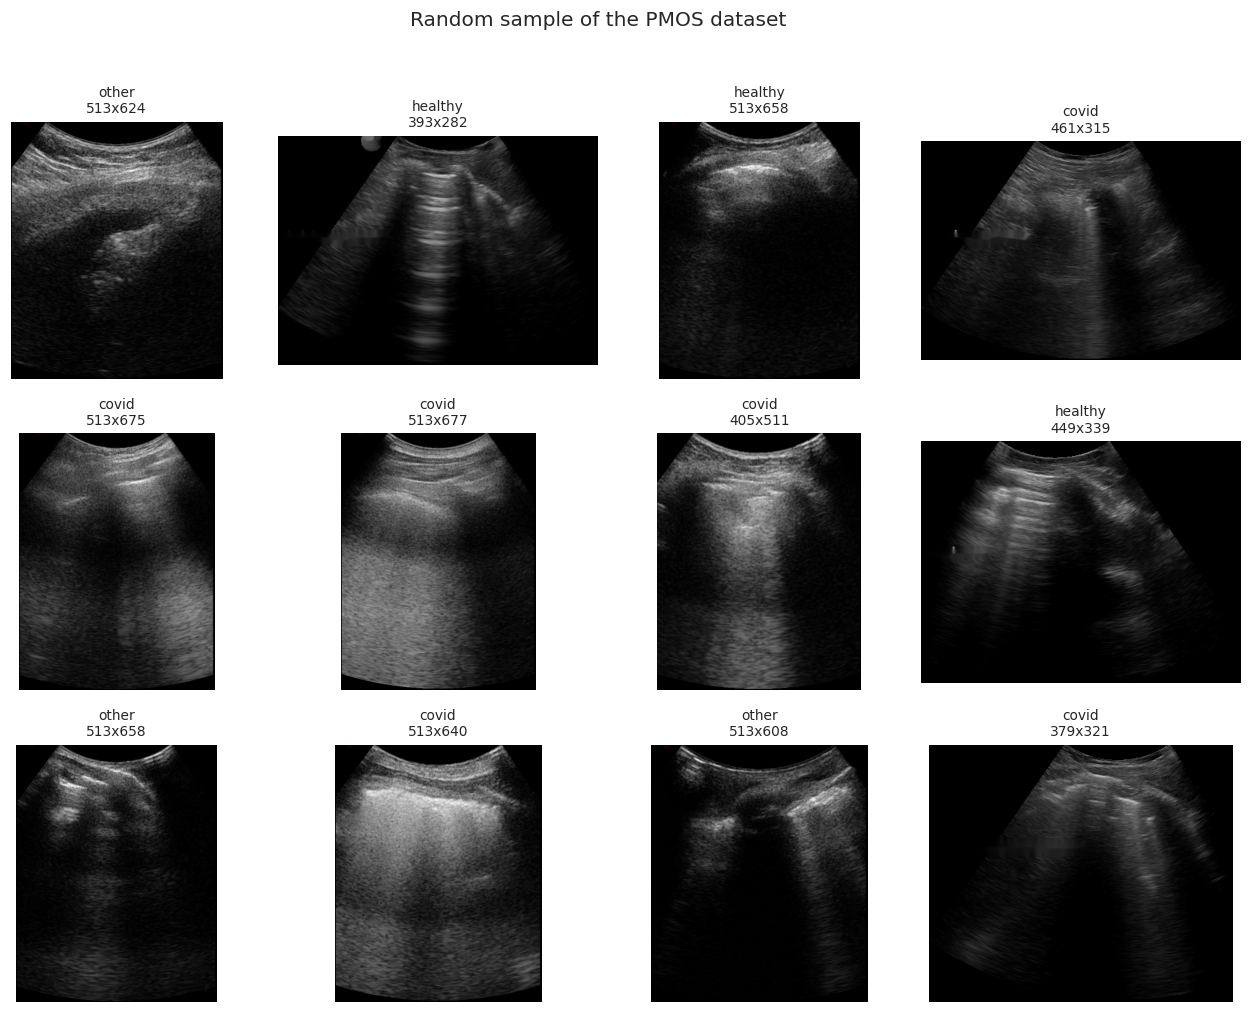

In [20]:
# --- 5.3 Random sample grid ---------------------------------------------
sample_df = df_images.sample(n=min(12, len(df_images)), random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, row) in zip(axes.flatten(), sample_df.iterrows()):
    img = Image.open(row["path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{row['class']}\n{img.size[0]}x{img.size[1]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Random sample of the PMOS dataset", y=1.02)
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/eda_sample_grid.png", bbox_inches="tight")
plt.show()


Sampling RGB means:   0%|          | 0/150 [00:00<?, ?it/s]

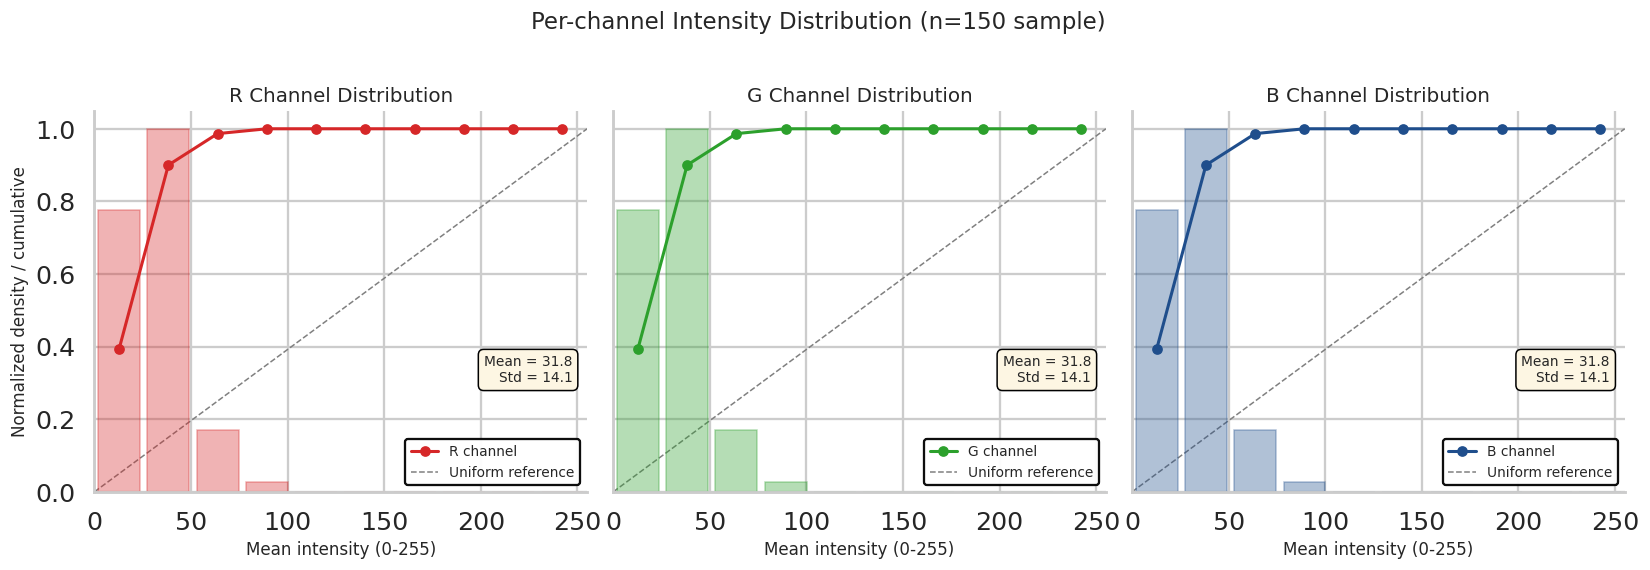

In [21]:
# --- 5.4 RGB channel intensity distribution (legend bottom-right) ----------
sample_for_rgb = df_images.sample(n=min(150, len(df_images)), random_state=SEED)
r_means, g_means, b_means = [], [], []
for p in tqdm(sample_for_rgb["path"], desc="Sampling RGB means"):
    arr = np.asarray(Image.open(p).convert("RGB").resize((128, 128)), dtype=np.float32)
    r_means.append(arr[..., 0].mean())
    g_means.append(arr[..., 1].mean())
    b_means.append(arr[..., 2].mean())

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
})

n_bins = 10
bin_edges = np.linspace(0, 255, n_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_width = (bin_edges[1] - bin_edges[0]) * 0.85

channels = [
    (np.array(r_means), "#d62728", "R"),
    (np.array(g_means), "#2ca02c", "G"),
    (np.array(b_means), "#1f4e8c", "B"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, (vals, color, label) in zip(axes, channels):
    counts, _ = np.histogram(vals, bins=bin_edges)
    density = counts / counts.sum()
    cum_norm = np.cumsum(density)

    ax.bar(bin_centers, density / density.max(), width=bin_width,
           color=color, alpha=0.35, edgecolor=color, linewidth=1, zorder=2)

    ax.plot(bin_centers, cum_norm, color=color, marker="o", markersize=6,
             linewidth=2, zorder=3, label=f"{label} channel")

    ax.plot([0, 255], [0, 1], linestyle="--", color="gray", linewidth=1, zorder=1,
             label="Uniform reference")

    ax.set_title(f"{label} Channel Distribution", fontsize=13)
    ax.set_xlabel("Mean intensity (0-255)", fontsize=11)
    if ax is axes[0]:
        ax.set_ylabel("Normalized density / cumulative", fontsize=11)

    ax.set_xlim(0, 255)
    ax.set_ylim(0, 1.05)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # legend moved to bottom-right
    ax.legend(loc="lower right", frameon=True, framealpha=0.95,
               edgecolor="black", fontsize=9)

    # stat box placed just above the legend, still bottom-right
    ax.text(0.97, 0.28, f"Mean = {vals.mean():.1f}\nStd = {vals.std():.1f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="#fdf6e3",
                      edgecolor="black", linewidth=1))

fig.suptitle(f"Per-channel Intensity Distribution (n={len(sample_for_rgb)} sample)",
             fontsize=15, y=1.03)

plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/eda_rgb_distribution.png", bbox_inches="tight", dpi=300)
plt.show()

In [22]:
# --- 5.5 Basic statistics summary table ---------------------------------
summary_stats = {
    "total_images": len(df_images),
    "classes": df_images["class"].value_counts().to_dict(),
    "width_mean": float(df_images["width"].mean()),
    "width_std": float(df_images["width"].std()),
    "height_mean": float(df_images["height"].mean()),
    "height_std": float(df_images["height"].std()),
    "aspect_ratio_mean": float(df_images["aspect_ratio"].mean()),
}
print(json.dumps(summary_stats, indent=2))


{
  "total_images": 1062,
  "classes": {
    "other": 362,
    "healthy": 362,
    "covid": 338
  },
  "width_mean": 438.89924670433146,
  "width_std": 76.6026395858193,
  "height_mean": 489.9425612052731,
  "height_std": 136.82877808070575,
  "aspect_ratio_mean": 0.9407208249500302
}


## 6. Dataset Preparation

Verify every image is readable (drop any corrupt / zero-byte files) before committing GPU time to training. No train/validation/test split is created: this is **unconditional generative modeling**, so the full cleaned image pool is used both (a) for GAN fine-tuning and (b) as the real-image reference distribution for FID/KID in Sections 14-15 — this is standard practice for GAN evaluation on small datasets.


In [23]:
def verify_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        # re-open (verify() invalidates the file handle) to confirm full decode
        with Image.open(path) as im:
            im.convert("RGB").load()
        return True
    except Exception:
        return False


tqdm.pandas(desc="Verifying images")
df_images["is_valid"] = df_images["path"].progress_apply(verify_image)

n_bad = (~df_images["is_valid"]).sum()
if n_bad > 0:
    print(f"Dropping {n_bad} unreadable/corrupt image(s).")
df_clean = df_images[df_images["is_valid"]].reset_index(drop=True)

print(f"Final clean dataset: {len(df_clean)} images "
      f"({df_clean['class'].value_counts().to_dict()})")


Verifying images:   0%|          | 0/1062 [00:00<?, ?it/s]

Final clean dataset: 1062 images ({'other': 362, 'healthy': 362, 'covid': 338})


## 7. Resize Images (256&times;256)

All images are resized to a uniform **256&times;256 RGB** canvas: shorter side is resized with high-quality Lanczos resampling, then center-cropped to a square. Images are saved as **PNG** (lossless) — re-encoding to JPEG at this stage would inject compression artifacts that bias FID/KID computed later.


In [24]:
IMG_SIZE = 256

def resize_center_crop(img, size=256):
    img = img.convert("RGB")
    w, h = img.size
    scale = size / min(w, h)
    new_w, new_h = round(w * scale), round(h * scale)
    img = img.resize((new_w, new_h), Image.LANCZOS)
    left = (new_w - size) // 2
    top = (new_h - size) // 2
    return img.crop((left, top, left + size, top + size))


shutil.rmtree(PATHS["processed"], ignore_errors=True)
os.makedirs(PATHS["processed"], exist_ok=True)

processed_paths = []
for i, row in tqdm(df_clean.iterrows(), total=len(df_clean), desc="Resizing to 256x256"):
    try:
        img = Image.open(row["path"])
        img = resize_center_crop(img, IMG_SIZE)
        out_name = f"{i:05d}_{row['class'].replace(' ', '-')}.png"
        out_path = os.path.join(PATHS["processed"], out_name)
        img.save(out_path, format="PNG")
        processed_paths.append(out_path)
    except Exception as e:
        print(f"Skipped {row['path']}: {e}")

print(f"Processed and saved {len(processed_paths)} images to {PATHS['processed']}")


Resizing to 256x256:   0%|          | 0/1062 [00:00<?, ?it/s]

Processed and saved 1062 images to /kaggle/working/data/processed_256


In [25]:
# Sanity check: confirm every processed file is exactly 256x256 RGB
bad = []
for p in tqdm(processed_paths[:200], desc="Spot-checking processed images"):
    with Image.open(p) as im:
        if im.size != (IMG_SIZE, IMG_SIZE) or im.mode != "RGB":
            bad.append(p)
print("Spot-check issues found:", len(bad))


Spot-checking processed images:   0%|          | 0/200 [00:00<?, ?it/s]

Spot-check issues found: 0


## 8. Convert Dataset to StyleGAN Format

We clone the **official NVIDIA `stylegan2-ada-pytorch` repository** (chosen over the original TensorFlow implementation because it runs cleanly on modern PyTorch + a single/dual T4, and is the version transfer-learning source checkpoints are published for). Its bundled `dataset_tool.py` packs the processed images into the zip archive format the training loop expects.

> **Switching to class-conditional training later:** `dataset_tool.py` supports a `dataset.json` label file per image for class-conditional GANs. If you decide to condition on `PMOS` / `NON PMOS`, keep images in per-class sub-folders (instead of the flat `processed_256/` folder used here) and pass that folder to `dataset_tool.py` — it auto-generates labels from sub-folder names.


In [26]:
REPO_DIR = PATHS["repo"]

if not os.path.isfile(f"{REPO_DIR}/dataset_tool.py"):
    # folder may already exist (empty) from Section 0's os.makedirs — remove it first
    # so git clone doesn't complain about a non-empty/pre-existing target
    shutil.rmtree(REPO_DIR, ignore_errors=True)

    result = subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/NVlabs/stylegan2-ada-pytorch.git", REPO_DIR],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        raise RuntimeError(f"git clone failed:\n{result.stderr}")
    print("Cloned stylegan2-ada-pytorch.")
else:
    print("Repo already present, skipping clone.")

assert os.path.isfile(f"{REPO_DIR}/dataset_tool.py"), "dataset_tool.py not found — clone may have failed."

Cloned stylegan2-ada-pytorch.


In [27]:
misc_path = f"{REPO_DIR}/torch_utils/misc.py"

with open(misc_path, "r") as f:
    content = f.read()

old = "        super().__init__(dataset)"
new = "        super().__init__()"

if old in content:
    content = content.replace(old, new)
    with open(misc_path, "w") as f:
        f.write(content)
    print("Patched: InfiniteSampler is now compatible with the current PyTorch Sampler API.")
elif new in content:
    print("Already patched — nothing to do.")
else:
    print("Expected line not found. Check manually:", misc_path)


Patched: InfiniteSampler is now compatible with the current PyTorch Sampler API.


In [28]:
grid_sample_path = f"{REPO_DIR}/torch_utils/ops/grid_sample_gradfix.py"

with open(grid_sample_path, "r") as f:
    content = f.read()

old = """def _should_use_custom_op():
    if not enabled:
        return False
    if any(torch.__version__.startswith(x) for x in ['1.7.', '1.8.', '1.9']):
        return True
    warnings.warn(f'grid_sample_gradfix not supported on PyTorch {torch.__version__}. Falling back to torch.nn.functional.grid_sample().')
    return False"""

new = """def _should_use_custom_op():
    # Patched: the original hardcoded version whitelist (1.7-1.9) doesn't
    # recognize modern PyTorch, forcing a fallback to torch.nn.functional.grid_sample()
    # which lacks a double-backward implementation -> crashes on R1 regularization.
    # The custom op itself (torch._C._jit_get_operation('aten::grid_sampler_2d_backward'))
    # still works fine on current PyTorch, so just trust the `enabled` flag.
    return enabled"""

if old in content:
    content = content.replace(old, new)
    with open(grid_sample_path, "w") as f:
        f.write(content)
    print("Patched grid_sample_gradfix.py: custom double-backward grid_sample re-enabled.")
elif "return enabled" in content and "_should_use_custom_op" in content:
    print("Already patched — nothing to do.")
else:
    print("Expected function body not found — file may differ. Check manually:")
    print(grid_sample_path)

Patched grid_sample_gradfix.py: custom double-backward grid_sample re-enabled.


In [29]:
grid_sample_path = f"{REPO_DIR}/torch_utils/ops/grid_sample_gradfix.py"

with open(grid_sample_path, "r") as f:
    content = f.read()

old = """    @staticmethod
    def forward(ctx, grad_output, input, grid):
        op = torch._C._jit_get_operation('aten::grid_sampler_2d_backward')
        grad_input, grad_grid = op(grad_output, input, grid, 0, 0, False)
        ctx.save_for_backward(grid)
        return grad_input, grad_grid"""

new = """    @staticmethod
    def forward(ctx, grad_output, input, grid):
        op = torch._C._jit_get_operation('aten::grid_sampler_2d_backward')
        # Patched: modern PyTorch returns (op, overload_names) instead of a
        # directly-callable op, and the ATen signature gained an extra
        # `output_mask` argument. Handle both old and new APIs.
        if isinstance(op, tuple):
            op = op[0]
        try:
            grad_input, grad_grid = op(grad_output, input, grid, 0, 0, False, (True, True))
        except TypeError:
            grad_input, grad_grid = op(grad_output, input, grid, 0, 0, False)
        ctx.save_for_backward(grid)
        return grad_input, grad_grid"""

if old in content:
    content = content.replace(old, new)
    with open(grid_sample_path, "w") as f:
        f.write(content)
    print("Patched grid_sample_gradfix.py: fixed the _jit_get_operation tuple/output_mask API change.")
elif "if isinstance(op, tuple):" in content:
    print("Already patched — nothing to do.")
else:
    print("Expected function body not found — file may differ. Check manually:")
    print(grid_sample_path)

Patched grid_sample_gradfix.py: fixed the _jit_get_operation tuple/output_mask API change.


In [30]:
upfirdn2d_path = f"{REPO_DIR}/torch_utils/ops/upfirdn2d.py"
with open(upfirdn2d_path, "r") as f:
    content = f.read()

old = """        try:
            _plugin = custom_ops.get_plugin(\'upfirdn2d_plugin\', sources=sources, extra_cuda_cflags=[\'--use_fast_math\'])
        except:
            warnings.warn(\'Failed to build CUDA kernels for upfirdn2d. Falling back to slow reference implementation. Details:\\n\\n\' + traceback.format_exc())
    return _plugin is not None"""
new = """        try:
            _plugin = custom_ops.get_plugin(\'upfirdn2d_plugin\', sources=sources, extra_cuda_cflags=[\'--use_fast_math\'])
        except:
            warnings.warn(\'Failed to build CUDA kernels for upfirdn2d. Falling back to slow reference implementation. Details:\\n\\n\' + traceback.format_exc())
        _inited = True  # Patched: only attempt CUDA build once.
    return _plugin is not None"""

if old in content:
    content = content.replace(old, new)
    with open(upfirdn2d_path, "w") as f:
        f.write(content)
    print("Patched upfirdn2d.py: CUDA build is now only attempted once.")
elif "_inited = True  # Patched" in content:
    print("Already patched — nothing to do.")
else:
    print("Expected block not found — check manually:", upfirdn2d_path)

bias_act_path = f"{REPO_DIR}/torch_utils/ops/bias_act.py"
with open(bias_act_path, "r") as f:
    ba_content = f.read()

ba_old = """        try:
            _plugin = custom_ops.get_plugin(\'bias_act_plugin\', sources=sources, extra_cuda_cflags=[\'--use_fast_math\'])
        except:
            warnings.warn(\'Failed to build CUDA kernels for bias_act. Falling back to slow reference implementation. Details:\\n\\n\' + traceback.format_exc())
    return _plugin is not None"""
ba_new = """        try:
            _plugin = custom_ops.get_plugin(\'bias_act_plugin\', sources=sources, extra_cuda_cflags=[\'--use_fast_math\'])
        except:
            warnings.warn(\'Failed to build CUDA kernels for bias_act. Falling back to slow reference implementation. Details:\\n\\n\' + traceback.format_exc())
        _inited = True  # Patched: only attempt CUDA build once.
    return _plugin is not None"""

if ba_old in ba_content:
    ba_content = ba_content.replace(ba_old, ba_new)
    with open(bias_act_path, "w") as f:
        f.write(ba_content)
    print("Patched bias_act.py: CUDA build is now only attempted once.")
elif "_inited = True  # Patched" in ba_content:
    print("Already patched — nothing to do.")
else:
    print("bias_act.py pattern not found or differs — check manually:", bias_act_path)


Patched upfirdn2d.py: CUDA build is now only attempted once.
Patched bias_act.py: CUDA build is now only attempted once.


In [31]:
conv2d_path = f"{REPO_DIR}/torch_utils/ops/conv2d_gradfix.py"
with open(conv2d_path, "r") as f:
    content = f.read()

old_warn = "warnings.warn(f'conv2d_gradfix not supported on PyTorch {torch.__version__}. Falling back to torch.nn.functional.conv2d().')"
new_warn = """if not globals().get('_warned_conv2d_fallback', False):
            warnings.warn(f'conv2d_gradfix not supported on PyTorch {torch.__version__}. Falling back to torch.nn.functional.conv2d().')
            globals()['_warned_conv2d_fallback'] = True"""

if old_warn in content:
    content = content.replace(old_warn, new_warn)
    with open(conv2d_path, "w") as f:
        f.write(content)
    print("Patched conv2d_gradfix.py: warning now prints only once instead of on every call "
          "(this op is called constantly during training -- unpatched, it can bloat the log "
          "file to millions of lines over a multi-hour run and slow things down).")
elif "_warned_conv2d_fallback" in content:
    print("Already patched — nothing to do.")
else:
    print("Pattern not found — check manually:", conv2d_path)


Patched conv2d_gradfix.py: warning now prints only once instead of on every call (this op is called constantly during training -- unpatched, it can bloat the log file to millions of lines over a multi-hour run and slow things down).


In [32]:
STYLEGAN_ZIP = f"{PATHS['data']}/pmos_256.zip"

if os.path.exists(STYLEGAN_ZIP):
    os.remove(STYLEGAN_ZIP)

cmd = [
    sys.executable, f"{REPO_DIR}/dataset_tool.py",
    f"--source={PATHS['processed']}",
    f"--dest={STYLEGAN_ZIP}",
    f"--width={IMG_SIZE}",
    f"--height={IMG_SIZE}",
]
result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout[-2000:])
if result.returncode != 0:
    raise RuntimeError(f"dataset_tool.py failed:\n{result.stderr[-2000:]}")

assert os.path.isfile(STYLEGAN_ZIP), "Dataset zip was not created."
print(f"\nStyleGAN-format dataset ready: {STYLEGAN_ZIP} "
      f"({os.path.getsize(STYLEGAN_ZIP) / 1e6:.1f} MB)")




StyleGAN-format dataset ready: /kaggle/working/data/pmos_256.zip (209.3 MB)


## 9. Download Pretrained StyleGAN2-ADA

We fine-tune from the official **FFHQ-256** transfer-learning source network published by NVIDIA. Even though FFHQ is a face dataset (not medical), StyleGAN2-ADA's own transfer-learning experiments show that low-level convolutional features (edges, textures, gradients) transfer well across visually distant domains and substantially cut the number of images needed for a small target dataset like ours — this is the core justification for transfer learning over training from scratch.

Downloaded once to a local path (rather than relying on the `--resume=ffhq256` shortcut's internal caching) so the exact checkpoint used is a visible, reproducible artifact of this notebook.


In [33]:
PRETRAINED_URL = (
    "https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/"
    "transfer-learning-source-nets/ffhq-res256-mirror-paper256-noaug.pkl"
)
PRETRAINED_PATH = f"{PATHS['pretrained']}/ffhq256.pkl"

def download_with_progress(url, dest):
    import requests
    if os.path.exists(dest) and os.path.getsize(dest) > 1_000_000:
        print(f"Already downloaded: {dest}")
        return
    resp = requests.get(url, stream=True, timeout=60)
    resp.raise_for_status()
    total = int(resp.headers.get("content-length", 0))
    with open(dest, "wb") as f, tqdm(
        total=total, unit="B", unit_scale=True, desc="Downloading FFHQ-256 source net"
    ) as bar:
        for chunk in resp.iter_content(chunk_size=1 << 20):
            f.write(chunk)
            bar.update(len(chunk))

download_with_progress(PRETRAINED_URL, PRETRAINED_PATH)
print(f"\nPretrained network ready: {PRETRAINED_PATH} "
      f"({os.path.getsize(PRETRAINED_PATH) / 1e6:.1f} MB)")



Pretrained network ready: /kaggle/working/pretrained/ffhq256.pkl (295.7 MB)


## 10. Configure Training

Hyperparameters follow the official repo's own recommendation for **custom, small datasets**: `--cfg=auto`, which automatically derives batch size, learning rate and the R1 regularization weight (`gamma`) from the resolution and GPU count — this directly satisfies the "choose the best batch size automatically" requirement and is the setting the NVIDIA authors themselves recommend over hand-tuning for non-benchmark datasets.

| Setting | Value | Why |
|---|---|---|
| `cfg` | `auto` | Auto-selects batch size / lr / gamma for our resolution & GPU count |
| `resume` | FFHQ-256 checkpoint | Transfer learning, not from-scratch training |
| `aug` | `ada` | Adaptive discriminator augmentation — essential for a ~700-image dataset |
| `mirror` | `1` | Free 2x data augmentation via horizontal flips (safe for these images) |
| `snap` | `4` | Save a checkpoint every ~4 ticks (~16 kimg) — frequent enough to time-box safely |
| `metrics` | `none` | Built-in `fid50k_full` is far too expensive for 730 images / our time budget; we compute our own FID/KID post-hoc in Sections 14-15 on checkpoints actually saved |
| `workers` | auto (`min(cpu_count, 8)`) | Optimized data-loading parallelism |
| Mixed precision | automatic | `cfg=auto` enables fp16 in the highest-resolution synthesis/discriminator blocks natively |
| EMA | automatic | The official training loop always maintains an EMA copy of the generator (`G_ema`), which is what we use for all evaluation/generation |

**Time budget:** total training length is controlled by wall-clock in Section 11 (`MAX_TRAIN_HOURS`), not a fixed `kimg` target — this makes the notebook adapt automatically to whichever GPU (single/dual T4) the session gets, while still landing inside the ~6-7 hour goal.


In [34]:
QUICK_SMOKE_TEST = False   # <-- set True only for a fast plumbing check (few min); False = real training run

TRAIN_CONFIG = {
    "outdir": PATHS["runs"],
    "data": STYLEGAN_ZIP,
    "gpus": 1,
    "cfg": "auto",
    "resume": PRETRAINED_PATH,
    "aug": "ada",
    "mirror": 1,
    "snap": 1 if QUICK_SMOKE_TEST else 4,   # FIXED: snap=1 for every run meant every checkpoint
                                             # is saved every ~4 kimg (kimg_per_tick default) --
                                             # over a real 4-5h run that's 100+ full-size .pkl
                                             # snapshots, risking Kaggle's disk quota and wasting
                                             # time on constant saving. snap=4 (~16 kimg interval,
                                             # matching the table in Section 10's markdown above)
                                             # gives plenty of checkpoints to pick a best-FID model
                                             # from without the disk/time cost.
    "metrics": "none",
    "workers": min(os.cpu_count() or 4, 8),
    "kimg": 3000,   # generous cap -- MAX_TRAIN_HOURS (wall-clock) is what actually governs a
                     # real run's length, so we don't have to guess a kimg target in advance.
    "seed": SEED,
}

# NOTE: FFHQ (face) -> medical-ultrasound is a large domain shift. train.py itself
# stops on its own once TRAIN_CONFIG["kimg"] is reached, but with kimg=3000 that would
# take far longer than one Kaggle session -- so in practice MAX_TRAIN_HOURS (wall-clock)
# is the real, deliberate control on how long training runs. When the deadline hits,
# run_training_timeboxed() (Section 11) stops train.py gracefully and the most recent
# snapshot on disk (at most ~16 kimg of progress old, thanks to snap=4 above) is used
# for everything downstream. Kaggle GPU sessions cap out around ~9-12h continuous
# (check your weekly GPU quota under Account -> Settings), so keep this comfortably
# under that ceiling.
MAX_TRAIN_HOURS = 0.15 if QUICK_SMOKE_TEST else 5.0

print(json.dumps(TRAIN_CONFIG, indent=2))
print(f"\nQUICK_SMOKE_TEST = {QUICK_SMOKE_TEST}")
print(f"MAX_TRAIN_HOURS = {MAX_TRAIN_HOURS}")

{
  "outdir": "/kaggle/working/training-runs",
  "data": "/kaggle/working/data/pmos_256.zip",
  "gpus": 1,
  "cfg": "auto",
  "resume": "/kaggle/working/pretrained/ffhq256.pkl",
  "aug": "ada",
  "mirror": 1,
  "snap": 4,
  "metrics": "none",
  "workers": 4,
  "kimg": 3000,
  "seed": 42
}

QUICK_SMOKE_TEST = False
MAX_TRAIN_HOURS = 5.0


## 11. Start Fine-tuning

Launches the official `train.py` as a background subprocess and polls it. Because `--snap=4` checkpoints the model every ~16 kimg, we can safely **terminate training once the wall-clock budget (`MAX_TRAIN_HOURS`) is reached** without losing more than a few minutes of progress — the most recent snapshot on disk is always usable.

Progress (tick, kimg processed, current loss values) is parsed from the run's `stats.jsonl` log and printed periodically so you can monitor training without flooding the notebook output.


In [35]:
# Clean slate: remove any leftover run folders / logs from earlier attempts
# (e.g. a QUICK_SMOKE_TEST run) so get_latest_run_dir() always picks up THIS
# run, and old snapshots don't waste disk space during the real training run.
shutil.rmtree(PATHS["runs"], ignore_errors=True)
os.makedirs(PATHS["runs"], exist_ok=True)
print("Cleared old training-runs — starting fresh.")


Cleared old training-runs — starting fresh.


In [36]:
loop_path = f"{REPO_DIR}/training/training_loop.py"

with open(loop_path, "r") as f:
    content = f.read()

old = "misc.check_ddp_consistency(module, ignore_regex=r'.*\\.w_avg')"
new = "misc.check_ddp_consistency(module, ignore_regex=r'.*\\.w_avg|.*\\.noise_const')"

if old in content:
    content = content.replace(old, new)
    with open(loop_path, "w") as f:
        f.write(content)
    print("Patched training_loop.py: noise_const excluded from DDP consistency check.")
elif "noise_const" in content and "ignore_regex" in content:
    print("Already patched — nothing to do.")
else:
    print("Expected line not found — check manually:", loop_path)

Patched training_loop.py: noise_const excluded from DDP consistency check.


In [37]:
def build_train_command(config):
    cmd = [sys.executable, f"{REPO_DIR}/train.py"]
    for k, v in config.items():
        cmd.append(f"--{k}={v}")
    return cmd


def get_latest_run_dir(runs_dir):
    run_dirs = sorted(glob.glob(f"{runs_dir}/0*"))
    return run_dirs[-1] if run_dirs else None


def tail_stats(run_dir, n=1):
    """Read the last n lines of stats.jsonl for a lightweight progress readout."""
    stats_path = os.path.join(run_dir, "stats.jsonl")
    if not os.path.isfile(stats_path):
        return []
    with open(stats_path) as f:
        lines = f.readlines()
    out = []
    for line in lines[-n:]:
        try:
            out.append(json.loads(line))
        except json.JSONDecodeError:
            continue
    return out

In [38]:
def run_training_timeboxed(config, max_hours, poll_seconds=30):
    cmd = build_train_command(config)
    log_path = f"{PATHS['runs']}/train_stdout.log"
    print("Launching:", " ".join(cmd))
    print(f"Time budget: {max_hours} hours -> hard cutoff at "
          f"{(datetime.now() + timedelta(hours=max_hours)).strftime('%H:%M:%S')}")

    log_f = open(log_path, "w")
    proc = subprocess.Popen(cmd, stdout=log_f, stderr=subprocess.STDOUT, cwd=REPO_DIR)
    start = time.time()
    deadline = start + max_hours * 3600
    run_dir = None

    try:
        with tqdm(total=int(max_hours * 3600), desc="Training (wall-clock budget)", unit="s") as bar:
            last_elapsed = 0
            while True:
                ret = proc.poll()
                elapsed = time.time() - start
                bar.update(int(elapsed - last_elapsed))
                last_elapsed = elapsed

                if ret is not None:
                    log_f.close()
                    print(f"\ntrain.py exited on its own (return code {ret}) after {elapsed/3600:.2f}h.")
                    if ret != 0:
                        print("\n--- Last 60 lines of train_stdout.log ---")
                        with open(log_path) as lf:
                            print("".join(lf.readlines()[-60:]))
                        raise RuntimeError(
                            f"train.py failed with return code {ret}. See log above / at {log_path}"
                        )
                    break

                if run_dir is None:
                    run_dir = get_latest_run_dir(PATHS["runs"])

                if run_dir is not None and int(elapsed) % 120 < poll_seconds:
                    stats = tail_stats(run_dir, n=1)
                    if stats:
                        s = stats[0]
                        kimg = s.get("Progress/kimg", {}).get("mean", "?")
                        gloss = s.get("Loss/G/loss", {}).get("mean", "?")
                        dloss = s.get("Loss/D/loss", {}).get("mean", "?")
                        tqdm.write(f"[{elapsed/3600:.2f}h] kimg={kimg} G_loss={gloss} D_loss={dloss}")

                if time.time() >= deadline:
                    print(f"\nTime budget of {max_hours}h reached — stopping training gracefully.")
                    proc.terminate()
                    try:
                        proc.wait(timeout=60)
                    except subprocess.TimeoutExpired:
                        proc.kill()
                    break

                time.sleep(poll_seconds)
    finally:
        if not log_f.closed:
            log_f.close()

    run_dir = run_dir or get_latest_run_dir(PATHS["runs"])
    total_hours = (time.time() - start) / 3600
    print(f"\nTraining stopped after {total_hours:.2f}h. Run directory: {run_dir}")
    return run_dir


RUN_DIR = run_training_timeboxed(TRAIN_CONFIG, MAX_TRAIN_HOURS)

Launching: /usr/bin/python3 /kaggle/working/stylegan2-ada-pytorch/train.py --outdir=/kaggle/working/training-runs --data=/kaggle/working/data/pmos_256.zip --gpus=1 --cfg=auto --resume=/kaggle/working/pretrained/ffhq256.pkl --aug=ada --mirror=1 --snap=4 --metrics=none --workers=4 --kimg=3000 --seed=42
Time budget: 5.0 hours -> hard cutoff at 12:07:55


Training (wall-clock budget):   0%|          | 0/18000 [00:00<?, ?s/s]

[0.07h] kimg=0.01600000075995922 G_loss=3.3217124938964844 D_loss=2.841190814971924
[0.10h] kimg=0.01600000075995922 G_loss=3.3217124938964844 D_loss=2.841190814971924
[0.13h] kimg=0.01600000075995922 G_loss=3.3217124938964844 D_loss=2.841190814971924
[0.17h] kimg=0.01600000075995922 G_loss=3.3217124938964844 D_loss=2.841190814971924
[0.20h] kimg=0.01600000075995922 G_loss=3.3217124938964844 D_loss=2.841190814971924
[0.23h] kimg=0.01600000075995922 G_loss=3.3217124938964844 D_loss=2.841190814971924
[0.27h] kimg=4.015999794006348 G_loss=4.3864649959784 D_loss=0.6003656981550157
[0.30h] kimg=4.015999794006348 G_loss=4.3864649959784 D_loss=0.6003656981550157
[0.33h] kimg=4.015999794006348 G_loss=4.3864649959784 D_loss=0.6003656981550157
[0.37h] kimg=4.015999794006348 G_loss=4.3864649959784 D_loss=0.6003656981550157
[0.40h] kimg=4.015999794006348 G_loss=4.3864649959784 D_loss=0.6003656981550157
[0.43h] kimg=4.015999794006348 G_loss=4.3864649959784 D_loss=0.6003656981550157
[0.47h] kimg=4.0

In [39]:
log_path = f"{PATHS['runs']}/train_stdout.log"
with open(log_path) as f:
    lines = f.readlines()

print(f"Total lines: {len(lines)}")
fail_count = sum(1 for l in lines if "Failed!" in l)
print(f"'Failed!' plugin messages found: {fail_count}")
print()
print("Last 40 lines:")
print("".join(lines[-40:]))

Total lines: 259
'Failed!' plugin messages found: 2

Last 40 lines:
b16.conv1      2359808     16       [16, 512, 8, 8]      float32 
b16            -           16       [16, 512, 8, 8]      float32 
b8.skip        262144      16       [16, 512, 4, 4]      float32 
b8.conv0       2359808     16       [16, 512, 8, 8]      float32 
b8.conv1       2359808     16       [16, 512, 4, 4]      float32 
b8             -           16       [16, 512, 4, 4]      float32 
b4.mbstd       -           -        [16, 513, 4, 4]      float32 
b4.conv        2364416     16       [16, 512, 4, 4]      float32 
b4.fc          4194816     -        [16, 512]            float32 
b4.out         513         -        [16, 1]              float32 
---            ---         ---      ---                  ---     
Total          24001089    416      -                    -       

Setting up augmentation...
Distributing across 1 GPUs...
Setting up training phases...
Exporting sample images...
Initializing logs...
Trai

In [40]:
snapshots = sorted(glob.glob(f"{RUN_DIR}/network-snapshot-*.pkl"))
print(f"Checkpoints saved ({len(snapshots)}):")
for s in snapshots:
    print(" ", os.path.basename(s))

assert len(snapshots) > 0, (
    "No checkpoints were saved. Training may have failed immediately — "
    f"check {PATHS['runs']}/train_stdout.log for errors."
)


Checkpoints saved (5):
  network-snapshot-000000.pkl
  network-snapshot-000016.pkl
  network-snapshot-000032.pkl
  network-snapshot-000048.pkl
  network-snapshot-000064.pkl


In [41]:
print("RUN_DIR:", RUN_DIR)
print("Exists:", os.path.isdir(RUN_DIR) if RUN_DIR else "RUN_DIR is None")
if RUN_DIR:
    print("Contents:", os.listdir(RUN_DIR))

RUN_DIR: /kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom
Exists: True
Contents: ['fakes_init.png', 'network-snapshot-000048.pkl', 'log.txt', 'fakes000032.png', 'fakes000048.png', 'fakes000064.png', 'network-snapshot-000032.pkl', 'stats.jsonl', 'reals.png', 'fakes000016.png', 'network-snapshot-000000.pkl', 'training_options.json', 'fakes000000.png', 'network-snapshot-000064.pkl', 'network-snapshot-000016.pkl', 'events.out.tfevents.1787987375.6c316a91c799.157.0']


## 12. Resume Training (contingency cell)

**Only run this cell if you need to continue training in a later Kaggle session** (e.g. the time budget above wasn't enough, or the session disconnected). `/kaggle/working` does **not** persist between sessions by default — before ending a session you want to resume later, save `training-runs/` as a Kaggle Dataset (or notebook output) and re-attach it as an input in the next session, then point `PRIOR_SNAPSHOT` at the saved `.pkl`.

This cell is **not executed** as part of the normal top-to-bottom run; it's here for reproducibility/documentation.


In [42]:
RESUME_TRAINING = False   # flip to True to actually resume
ADDITIONAL_HOURS = 2.0
PRIOR_SNAPSHOT = None      # e.g. "/kaggle/input/pmos-run-checkpoint/network-snapshot-000200.pkl"

if RESUME_TRAINING:
    assert PRIOR_SNAPSHOT and os.path.isfile(PRIOR_SNAPSHOT), "Set PRIOR_SNAPSHOT to a valid .pkl path."
    resume_config = dict(TRAIN_CONFIG)
    resume_config["resume"] = PRIOR_SNAPSHOT
    RUN_DIR = run_training_timeboxed(resume_config, ADDITIONAL_HOURS)
    snapshots = sorted(glob.glob(f"{RUN_DIR}/network-snapshot-*.pkl"))
    print(f"Resumed run directory: {RUN_DIR} ({len(snapshots)} checkpoints)")
else:
    print("RESUME_TRAINING is False — skipping (this is expected on a normal full run).")


RESUME_TRAINING is False — skipping (this is expected on a normal full run).


## 13. Generate Evaluation Images per Checkpoint

Before picking a "best" model we need comparable image batches from every saved checkpoint. To keep runtime bounded, checkpoints are generated **in-process** (loading each `.pkl` once via the repo's own `legacy.py` loader, reusing CUDA context) rather than shelling out to `generate.py` per checkpoint, and evaluation batches are capped to `N_EVAL` images.

If more than `MAX_CHECKPOINTS_TO_EVAL` snapshots were saved, we evenly subsample them so the checkpoint-selection stage stays fast — the final checkpoints (closest to the end of training) are always included.


In [43]:
sys.path.insert(0, REPO_DIR)
import legacy   # from the cloned repo
import dnnlib

N_EVAL = 20 if QUICK_SMOKE_TEST else 300           # images generated per checkpoint for FID/KID comparison
MAX_CHECKPOINTS_TO_EVAL = 1 if QUICK_SMOKE_TEST else 10   # cap to bound evaluation time
EVAL_BATCH = 8 if QUICK_SMOKE_TEST else 16

def subsample_checkpoints(snapshots, max_n):
    if len(snapshots) <= max_n:
        return snapshots
    idx = np.linspace(0, len(snapshots) - 1, max_n - 1).astype(int).tolist()
    idx = sorted(set(idx + [len(snapshots) - 1]))
    return [snapshots[i] for i in idx]


eval_snapshots = subsample_checkpoints(snapshots, MAX_CHECKPOINTS_TO_EVAL)
print(f"Evaluating {len(eval_snapshots)} / {len(snapshots)} checkpoints: "
      f"{[os.path.basename(s) for s in eval_snapshots]}")


Evaluating 5 / 5 checkpoints: ['network-snapshot-000000.pkl', 'network-snapshot-000016.pkl', 'network-snapshot-000032.pkl', 'network-snapshot-000048.pkl', 'network-snapshot-000064.pkl']


In [44]:
def load_generator(pkl_path):
    with dnnlib.util.open_url(pkl_path) as f:
        data = legacy.load_network_pkl(f)
    G_ema = data["G_ema"].to(DEVICE).eval()
    return G_ema


@torch.no_grad()
def generate_batch(G, n_images, seed_offset=0, truncation_psi=1.0, batch_size=EVAL_BATCH):
    """Generate n_images from generator G, returned as a list of HxWx3 uint8 arrays."""
    imgs = []
    n_done = 0
    while n_done < n_images:
        cur_bs = min(batch_size, n_images - n_done)
        seeds = list(range(seed_offset + n_done, seed_offset + n_done + cur_bs))
        z = torch.from_numpy(
            np.stack([np.random.RandomState(s).randn(G.z_dim) for s in seeds])
        ).to(DEVICE).float()
        c = None
        if G.c_dim != 0:
            c = torch.zeros([cur_bs, G.c_dim], device=DEVICE)
        img = G(z, c, truncation_psi=truncation_psi, noise_mode="const")
        img = (img.clamp(-1, 1) + 1) * 127.5
        img = img.permute(0, 2, 3, 1).to(torch.uint8).cpu().numpy()
        imgs.extend([im for im in img])
        n_done += cur_bs
    return imgs


def save_images(imgs, out_dir, prefix="img"):
    os.makedirs(out_dir, exist_ok=True)
    for i, im in enumerate(imgs):
        Image.fromarray(im).save(f"{out_dir}/{prefix}_{i:05d}.png")


In [45]:
eval_root = f"{PATHS['metrics']}/eval_generations"
shutil.rmtree(eval_root, ignore_errors=True)

checkpoint_names = []
for pkl_path in tqdm(eval_snapshots, desc="Generating eval batches per checkpoint"):
    name = os.path.splitext(os.path.basename(pkl_path))[0]
    checkpoint_names.append(name)
    out_dir = f"{eval_root}/{name}"
    if os.path.isdir(out_dir) and len(os.listdir(out_dir)) >= N_EVAL:
        continue
    G = load_generator(pkl_path)
    imgs = generate_batch(G, N_EVAL, seed_offset=0, truncation_psi=1.0)  # trunc=1.0: unbiased for metrics
    save_images(imgs, out_dir)
    del G
    torch.cuda.empty_cache()

print(f"Saved evaluation batches for {len(checkpoint_names)} checkpoints under {eval_root}")


Generating eval batches per checkpoint:   0%|          | 0/5 [00:00<?, ?it/s]

Setting up PyTorch plugin "bias_act_plugin"... Failed!
Setting up PyTorch plugin "upfirdn2d_plugin"... Failed!
Saved evaluation batches for 5 checkpoints under /kaggle/working/metrics/eval_generations


## 14. Calculate FID

Fréchet Inception Distance between the **real, resized 256&times;256 images** (Section 7) and each checkpoint's evaluation batch (Section 13), using `torchmetrics`' InceptionV3-based implementation (`torch-fidelity` backend) — a well-validated FID implementation rather than a hand-rolled one, important for a Q1-journal-quality evaluation.


In [46]:
from torchmetrics.image.fid import FrechetInceptionDistance

def images_to_uint8_tensor(image_paths, size=256):
    """Load a list of image paths into a single uint8 NCHW tensor for torchmetrics."""
    arrs = []
    for p in image_paths:
        im = Image.open(p).convert("RGB").resize((size, size))
        arrs.append(np.asarray(im))
    arr = np.stack(arrs)                     # N,H,W,C
    t = torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()  # N,C,H,W
    return t


real_paths = sorted(glob.glob(f"{PATHS['processed']}/*.png"))
print(f"Real reference set: {len(real_paths)} images")


Real reference set: 1062 images


In [52]:
import os

# ==========================================================
# SEARCH FOR ALL GENERATED IMAGE FILES
# ==========================================================

SEARCH_ROOTS = [
    "/kaggle/working",
    "/kaggle/input"
]

image_extensions = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
)

found_images = []

for search_root in SEARCH_ROOTS:

    if not os.path.exists(search_root):
        continue

    for root, dirs, files in os.walk(search_root):

        for file in files:

            if file.lower().endswith(image_extensions):

                full_path = os.path.join(root, file)
                found_images.append(full_path)


# ==========================================================
# DISPLAY RESULTS
# ==========================================================

print("=" * 70)
print("GENERATED / IMAGE FILE SEARCH")
print("=" * 70)

print("Total image files found:", len(found_images))

print("\nFirst 100 image paths:\n")

for path in found_images[:100]:
    print(path)

GENERATED / IMAGE FILE SEARCH
Total image files found: 3638

First 100 image paths:

/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/fakes_init.png
/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/fakes000032.png
/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/fakes000048.png
/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/fakes000064.png
/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/reals.png
/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/fakes000016.png
/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/fakes000000.png
/kaggle/working/metrics/eval_generations/network-snapshot-000032/img_00063.png
/kaggle/working/metrics/eval_generations/network-snapshot-000032/img_00149.png
/kaggle/working/metrics/eval_generations/network-snapshot-000032

In [53]:
import os

print("=" * 70)
print("KAGGLE WORKING DIRECTORY")
print("=" * 70)

for root, dirs, files in os.walk("/kaggle/working"):

    level = root.replace(
        "/kaggle/working", ""
    ).count(os.sep)

    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

KAGGLE WORKING DIRECTORY
working/
  pretrained/
    ffhq256.pkl
  training-runs/
    train_stdout.log
    00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom/
      fakes_init.png
      network-snapshot-000048.pkl
      log.txt
      fakes000032.png
      fakes000048.png
      fakes000064.png
      network-snapshot-000032.pkl
      stats.jsonl
      reals.png
      fakes000016.png
  .virtual_documents/
    __notebook_source__.ipynb
  metrics/
    eval_generations/
      network-snapshot-000032/
        img_00063.png
        img_00149.png
        img_00055.png
        img_00145.png
        img_00059.png
        img_00209.png
        img_00049.png
        img_00278.png
        img_00264.png
        img_00198.png
      network-snapshot-000016/
        img_00063.png
        img_00149.png
        img_00055.png
        img_00145.png
        img_00059.png
        img_00209.png
        img_00049.png
        img_00278.png
        img_00264.png
        img_00198.png
      network-snapshot-0000

In [54]:
# ==========================================================
# COUNT ALL GAN-GENERATED IMAGES
# ==========================================================

import os
import pandas as pd

GAN_ROOT = "/kaggle/working/metrics/eval_generations"

IMAGE_EXTS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
)

snapshot_counts = {}

for snapshot in sorted(os.listdir(GAN_ROOT)):

    snapshot_path = os.path.join(
        GAN_ROOT,
        snapshot
    )

    if not os.path.isdir(snapshot_path):
        continue

    count = len([
        f for f in os.listdir(snapshot_path)
        if f.lower().endswith(IMAGE_EXTS)
    ])

    snapshot_counts[snapshot] = count


# ==========================================================
# DISPLAY
# ==========================================================

print("=" * 60)
print("GAN GENERATED IMAGE COUNT")
print("=" * 60)

for snapshot, count in snapshot_counts.items():
    print(f"{snapshot}: {count} images")

print(
    "\nTotal generated images across all snapshots:",
    sum(snapshot_counts.values())
)

GAN GENERATED IMAGE COUNT
network-snapshot-000000: 300 images
network-snapshot-000016: 300 images
network-snapshot-000032: 300 images
network-snapshot-000048: 300 images
network-snapshot-000064: 300 images

Total generated images across all snapshots: 1500


GAN SYNTHETIC IMAGE INFORMATION
Synthetic image directory:
/kaggle/working/metrics/eval_generations

CHECKPOINT-WISE SYNTHETIC IMAGE COUNT
network-snapshot-000000: 300 images
network-snapshot-000016: 300 images
network-snapshot-000032: 300 images
network-snapshot-000048: 300 images
network-snapshot-000064: 300 images

FINAL IMAGE COUNT
Total real images       : 1062
Total synthetic images  : 1500
Total combined images   : 2562

SYNTHETIC IMAGE TABLE
             Checkpoint  Synthetic Images
network-snapshot-000000               300
network-snapshot-000016               300
network-snapshot-000032               300
network-snapshot-000048               300
network-snapshot-000064               300


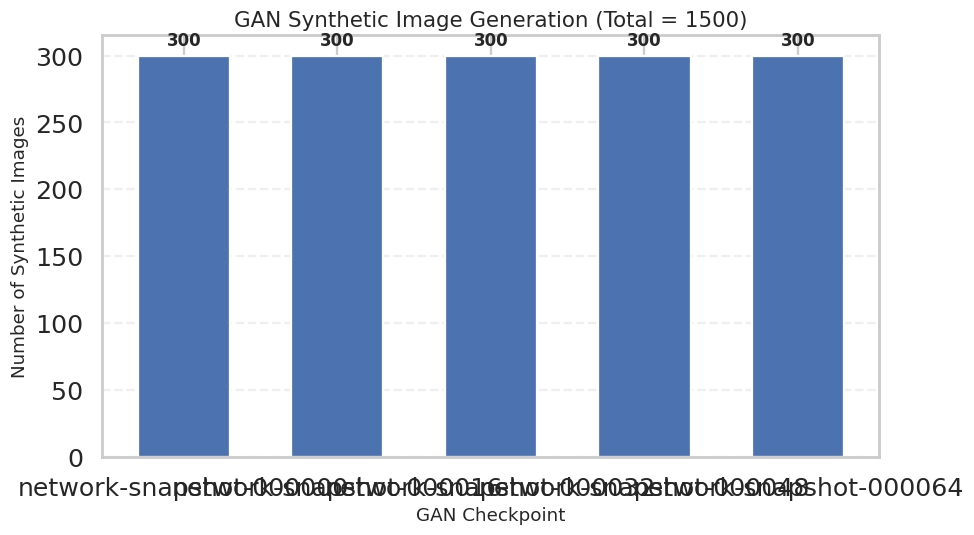


Chart saved to:
/kaggle/working/figures/gan_synthetic_image_count.png


In [56]:
# ==========================================================
# 19.6 GAN SYNTHETIC IMAGE COUNT
# REAL + SYNTHETIC SUMMARY
# ==========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ==========================================================
# 1. REAL DATA
# ==========================================================

class_names = sorted(
    df_clean["class"]
    .dropna()
    .unique()
    .tolist()
)

real_counts = (
    df_clean["class"]
    .value_counts()
)

total_real = int(
    real_counts.sum()
)


# ==========================================================
# 2. ACTUAL GAN GENERATED IMAGE DIRECTORY
# ==========================================================

GAN_GENERATED_DIR = (
    "/kaggle/working/metrics/eval_generations"
)


# ==========================================================
# 3. CHECK DIRECTORY
# ==========================================================

if not os.path.isdir(GAN_GENERATED_DIR):

    raise FileNotFoundError(
        f"GAN generated image directory not found:\n"
        f"{GAN_GENERATED_DIR}"
    )


print("=" * 70)
print("GAN SYNTHETIC IMAGE INFORMATION")
print("=" * 70)

print(
    "Synthetic image directory:"
)
print(
    GAN_GENERATED_DIR
)


# ==========================================================
# 4. IMAGE EXTENSIONS
# ==========================================================

IMAGE_EXTS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
)


# ==========================================================
# 5. COUNT IMAGES FOR EACH CHECKPOINT
# ==========================================================

snapshot_counts = {}

snapshot_dirs = sorted([
    d
    for d in os.listdir(GAN_GENERATED_DIR)
    if os.path.isdir(
        os.path.join(
            GAN_GENERATED_DIR,
            d
        )
    )
])


for snapshot in snapshot_dirs:

    snapshot_path = os.path.join(
        GAN_GENERATED_DIR,
        snapshot
    )

    image_count = len([
        f
        for f in os.listdir(snapshot_path)
        if f.lower().endswith(IMAGE_EXTS)
    ])

    snapshot_counts[
        snapshot
    ] = image_count


# ==========================================================
# 6. TOTAL SYNTHETIC IMAGES
# ==========================================================

total_synthetic = sum(
    snapshot_counts.values()
)


# ==========================================================
# 7. COMBINED TOTAL
# ==========================================================

total_combined = (
    total_real +
    total_synthetic
)


# ==========================================================
# 8. PRINT CHECKPOINT-WISE RESULTS
# ==========================================================

print("\n" + "=" * 70)
print("CHECKPOINT-WISE SYNTHETIC IMAGE COUNT")
print("=" * 70)

for snapshot, count in snapshot_counts.items():

    print(
        f"{snapshot}: {count} images"
    )


# ==========================================================
# 9. FINAL SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("FINAL IMAGE COUNT")
print("=" * 70)

print(
    f"Total real images       : {total_real}"
)

print(
    f"Total synthetic images  : {total_synthetic}"
)

print(
    f"Total combined images   : {total_combined}"
)


# ==========================================================
# 10. CREATE CHECKPOINT DATAFRAME
# ==========================================================

synthetic_df = pd.DataFrame({

    "Checkpoint":
        list(snapshot_counts.keys()),

    "Synthetic Images":
        list(snapshot_counts.values())

})


print("\n" + "=" * 70)
print("SYNTHETIC IMAGE TABLE")
print("=" * 70)

print(
    synthetic_df.to_string(
        index=False
    )
)


# ==========================================================
# 11. BASIC BAR CHART
# ==========================================================

plt.figure(
    figsize=(9, 5)
)

bars = plt.bar(
    synthetic_df["Checkpoint"],
    synthetic_df["Synthetic Images"],
    width=0.6
)


# ==========================================================
# ADD VALUE LABELS
# ==========================================================

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        height + 5,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


# ==========================================================
# LABELS
# ==========================================================

plt.xlabel(
    "GAN Checkpoint",
    fontsize=12
)

plt.ylabel(
    "Number of Synthetic Images",
    fontsize=12
)

plt.title(
    f"GAN Synthetic Image Generation "
    f"(Total = {total_synthetic})",
    fontsize=14
)


# ==========================================================
# GRID
# ==========================================================

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


# ==========================================================
# LAYOUT
# ==========================================================

plt.tight_layout()


# ==========================================================
# SAVE FIGURE
# ==========================================================

if "PATHS" in globals() and "figures" in PATHS:

    chart_path = os.path.join(
        PATHS["figures"],
        "gan_synthetic_image_count.png"
    )

else:

    chart_path = (
        "/kaggle/working/"
        "gan_synthetic_image_count.png"
    )


plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================================
# FINAL PATH
# ==========================================================

print(
    "\nChart saved to:"
)

print(
    chart_path
)

In [57]:
def compute_fid(real_paths, fake_paths, batch_size=32, device=DEVICE):
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(device)

    for i in tqdm(range(0, len(real_paths), batch_size), desc="FID: real features", leave=False):
        batch = images_to_uint8_tensor(real_paths[i:i + batch_size]).to(device)
        fid.update(batch, real=True)

    for i in tqdm(range(0, len(fake_paths), batch_size), desc="FID: fake features", leave=False):
        batch = images_to_uint8_tensor(fake_paths[i:i + batch_size]).to(device)
        fid.update(batch, real=False)

    score = fid.compute().item()
    del fid
    torch.cuda.empty_cache()
    return score


fid_results = []
for name in tqdm(checkpoint_names, desc="Computing FID per checkpoint"):
    fake_paths = sorted(glob.glob(f"{eval_root}/{name}/*.png"))
    score = compute_fid(real_paths, fake_paths)
    fid_results.append({"checkpoint": name, "fid": score})
    print(f"{name}: FID = {score:.2f}")

df_fid = pd.DataFrame(fid_results)


Computing FID per checkpoint:   0%|          | 0/5 [00:00<?, ?it/s]

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth

  0%|          | 0.00/91.2M [00:00<?, ?B/s]
  1%|          | 896k/91.2M [00:00<00:10, 8.99MB/s]
 13%|█▎        | 12.1M/91.2M [00:00<00:01, 72.3MB/s]
 31%|███       | 28.0M/91.2M [00:00<00:00, 115MB/s] 
 48%|████▊     | 43.8M/91.2M [00:00<00:00, 132MB/s]
 66%|██████▌   | 59.8M/91.2M [00:00<00:00, 145MB/s]
 83%|████████▎ | 75.8M/91.2M [00:00<00:00, 152MB/s]
100%|██████████| 91.2M/91.2M [00:00<00:00, 132MB/s]


FID: real features:   0%|          | 0/34 [00:00<?, ?it/s]

FID: fake features:   0%|          | 0/10 [00:00<?, ?it/s]

network-snapshot-000000: FID = 361.55


...

FID: fake features:   0%|          | 0/10 [00:00<?, ?it/s]

network-snapshot-000048: FID = 117.94


FID: real features:   0%|          | 0/34 [00:00<?, ?it/s]

FID: fake features:   0%|          | 0/10 [00:00<?, ?it/s]

network-snapshot-000064: FID = 72.11


## 15. Calculate KID (+ optional LPIPS diversity)

**KID** (Kernel Inception Distance) is a complementary, unbiased alternative to FID that behaves more reliably on small sample sizes like ours — a useful cross-check given only ~700 real images.

**LPIPS** (optional, toggle with `ENABLE_LPIPS`) measures average pairwise perceptual diversity *within* each checkpoint's generated batch — high LPIPS indicates the generator hasn't collapsed to near-duplicate outputs. It's kept optional since pairwise comparisons scale quadratically; we use a small sub-sample to keep runtime negligible.


In [58]:
from torchmetrics.image.kid import KernelInceptionDistance

KID_SUBSET_SIZE = min(100, len(real_paths), N_EVAL)  # must be <= smaller of the two sets

def compute_kid(real_paths, fake_paths, subset_size=KID_SUBSET_SIZE, batch_size=32, device=DEVICE):
    kid = KernelInceptionDistance(feature=2048, subset_size=subset_size, normalize=False).to(device)

    for i in range(0, len(real_paths), batch_size):
        batch = images_to_uint8_tensor(real_paths[i:i + batch_size]).to(device)
        kid.update(batch, real=True)

    for i in range(0, len(fake_paths), batch_size):
        batch = images_to_uint8_tensor(fake_paths[i:i + batch_size]).to(device)
        kid.update(batch, real=False)

    mean, std = kid.compute()
    del kid
    torch.cuda.empty_cache()
    return mean.item(), std.item()


kid_results = []
for name in tqdm(checkpoint_names, desc="Computing KID per checkpoint"):
    fake_paths = sorted(glob.glob(f"{eval_root}/{name}/*.png"))
    mean, std = compute_kid(real_paths, fake_paths)
    kid_results.append({"checkpoint": name, "kid_mean": mean, "kid_std": std})
    print(f"{name}: KID = {mean:.4f} +/- {std:.4f}")

df_kid = pd.DataFrame(kid_results)


Computing KID per checkpoint:   0%|          | 0/5 [00:00<?, ?it/s]

network-snapshot-000000: KID = 0.3903 +/- 0.0098
network-snapshot-000016: KID = 0.1229 +/- 0.0075
network-snapshot-000032: KID = 0.0694 +/- 0.0073
network-snapshot-000048: KID = 0.0770 +/- 0.0076
network-snapshot-000064: KID = 0.0268 +/- 0.0045


In [59]:
ENABLE_LPIPS = True
LPIPS_SAMPLE = 10 if QUICK_SMOKE_TEST else 40   # small sample -> pairwise LPIPS is O(n^2)

lpips_results = []
if ENABLE_LPIPS:
    import lpips as lpips_lib
    lpips_model = lpips_lib.LPIPS(net="alex").to(DEVICE).eval()

    def load_lpips_tensor(path):
        im = Image.open(path).convert("RGB").resize((256, 256))
        arr = np.asarray(im, dtype=np.float32) / 127.5 - 1.0
        return torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)

    for name in tqdm(checkpoint_names, desc="Computing LPIPS diversity per checkpoint"):
        fake_paths = sorted(glob.glob(f"{eval_root}/{name}/*.png"))[:LPIPS_SAMPLE]
        tensors = torch.cat([load_lpips_tensor(p) for p in fake_paths]).to(DEVICE)
        dists = []
        with torch.no_grad():
            for i in range(len(tensors)):
                for j in range(i + 1, len(tensors)):
                    d = lpips_model(tensors[i:i+1], tensors[j:j+1]).item()
                    dists.append(d)
        lpips_results.append({"checkpoint": name, "lpips_diversity": float(np.mean(dists))})

    df_lpips = pd.DataFrame(lpips_results)
    del lpips_model
    torch.cuda.empty_cache()
else:
    df_lpips = pd.DataFrame(columns=["checkpoint", "lpips_diversity"])

print(df_lpips)


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 207MB/s]  


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth


Computing LPIPS diversity per checkpoint:   0%|          | 0/5 [00:00<?, ?it/s]

                checkpoint  lpips_diversity
0  network-snapshot-000000         0.537037
1  network-snapshot-000016         0.512769
2  network-snapshot-000032         0.456438
3  network-snapshot-000048         0.407813
4  network-snapshot-000064         0.449138


## 16. Save Best Model

Merge FID / KID (/ LPIPS) into one table, rank checkpoints by **FID (primary criterion)** with **KID as a tie-breaker**, and copy the winning `.pkl` to `results/best_model.pkl` — this becomes the single source of truth for all downstream generation.


In [60]:
df_metrics = df_fid.merge(df_kid, on="checkpoint")
if not df_lpips.empty:
    df_metrics = df_metrics.merge(df_lpips, on="checkpoint", how="left")

# extract kimg from checkpoint name (network-snapshot-XXXXXX) for readability/plots
df_metrics["kimg"] = df_metrics["checkpoint"].str.extract(r"(\d+)").astype(int)
df_metrics = df_metrics.sort_values("kimg").reset_index(drop=True)

df_metrics.to_csv(f"{PATHS['metrics']}/checkpoint_metrics.csv", index=False)
print(df_metrics.to_string(index=False))


             checkpoint        fid  kid_mean  kid_std  lpips_diversity  kimg
network-snapshot-000000 361.545227  0.390305 0.009770         0.537037     0
network-snapshot-000016 149.931305  0.122871 0.007544         0.512769    16
network-snapshot-000032 107.941597  0.069370 0.007342         0.456438    32
network-snapshot-000048 117.944107  0.077037 0.007563         0.407813    48
network-snapshot-000064  72.110802  0.026772 0.004500         0.449138    64


In [61]:
best_row = df_metrics.sort_values(["fid", "kid_mean"]).iloc[0]
best_checkpoint_name = best_row["checkpoint"]
best_checkpoint_path = f"{RUN_DIR}/{best_checkpoint_name}.pkl"

BEST_MODEL_PATH = f"{PATHS['results']}/best_model.pkl"
shutil.copy2(best_checkpoint_path, BEST_MODEL_PATH)

print(f"Best checkpoint : {best_checkpoint_name}")
print(f"  FID  = {best_row['fid']:.2f}")
print(f"  KID  = {best_row['kid_mean']:.4f} +/- {best_row['kid_std']:.4f}")
if "lpips_diversity" in best_row and not pd.isna(best_row["lpips_diversity"]):
    print(f"  LPIPS diversity = {best_row['lpips_diversity']:.4f}")
print(f"Saved to: {BEST_MODEL_PATH}")


Best checkpoint : network-snapshot-000064
  FID  = 72.11
  KID  = 0.0268 +/- 0.0045
  LPIPS diversity = 0.4491
Saved to: /kaggle/working/results/best_model.pkl


## 17. Export Final Synthetic Dataset

Using the selected best checkpoint, generate the final large-scale synthetic image set. We use a mild truncation (`TRUNCATION_PSI = 0.7`) for this export — standard practice for a "usable" synthetic image gallery/augmentation set, trading a small amount of diversity for higher per-image fidelity (note this differs from the `truncation_psi=1.0` used for the *metrics* in Sections 13-15, which must stay unbiased/untruncated for a fair FID/KID comparison against real data).


In [62]:
NUM_FINAL_IMAGES = 30 if QUICK_SMOKE_TEST else 4000     # smoke test: just enough to prove export+zip works
TRUNCATION_PSI = 0.7
GEN_BATCH = 8 if QUICK_SMOKE_TEST else 16

shutil.rmtree(PATHS["generated"], ignore_errors=True)
os.makedirs(PATHS["generated"], exist_ok=True)

G_best = load_generator(BEST_MODEL_PATH)

n_done = 0
with tqdm(total=NUM_FINAL_IMAGES, desc="Exporting final synthetic images") as bar:
    while n_done < NUM_FINAL_IMAGES:
        cur_bs = min(GEN_BATCH, NUM_FINAL_IMAGES - n_done)
        imgs = generate_batch(G_best, cur_bs, seed_offset=100_000 + n_done,
                               truncation_psi=TRUNCATION_PSI, batch_size=GEN_BATCH)
        for im in imgs:
            Image.fromarray(im).save(f"{PATHS['generated']}/synthetic_{n_done:05d}.png")
            n_done += 1
        bar.update(len(imgs))

del G_best
torch.cuda.empty_cache()
print(f"\nExported {n_done} synthetic images to {PATHS['generated']}")


Exporting final synthetic images:   0%|          | 0/4000 [00:00<?, ?it/s]


Exported 4000 synthetic images to /kaggle/working/generated


## 18. Publication Figures & Save Results

Generates the figure set typically expected in a GAN methods paper: a real-vs-synthetic comparison grid, a random synthetic gallery, the FID progression across checkpoints, and the generator/discriminator training loss curves (parsed from the official training log). All figures are saved at 300 DPI to `figures/`. Finally, a `results/summary.json` captures the full run configuration and final metrics, and everything under `results/` is zipped for easy download.


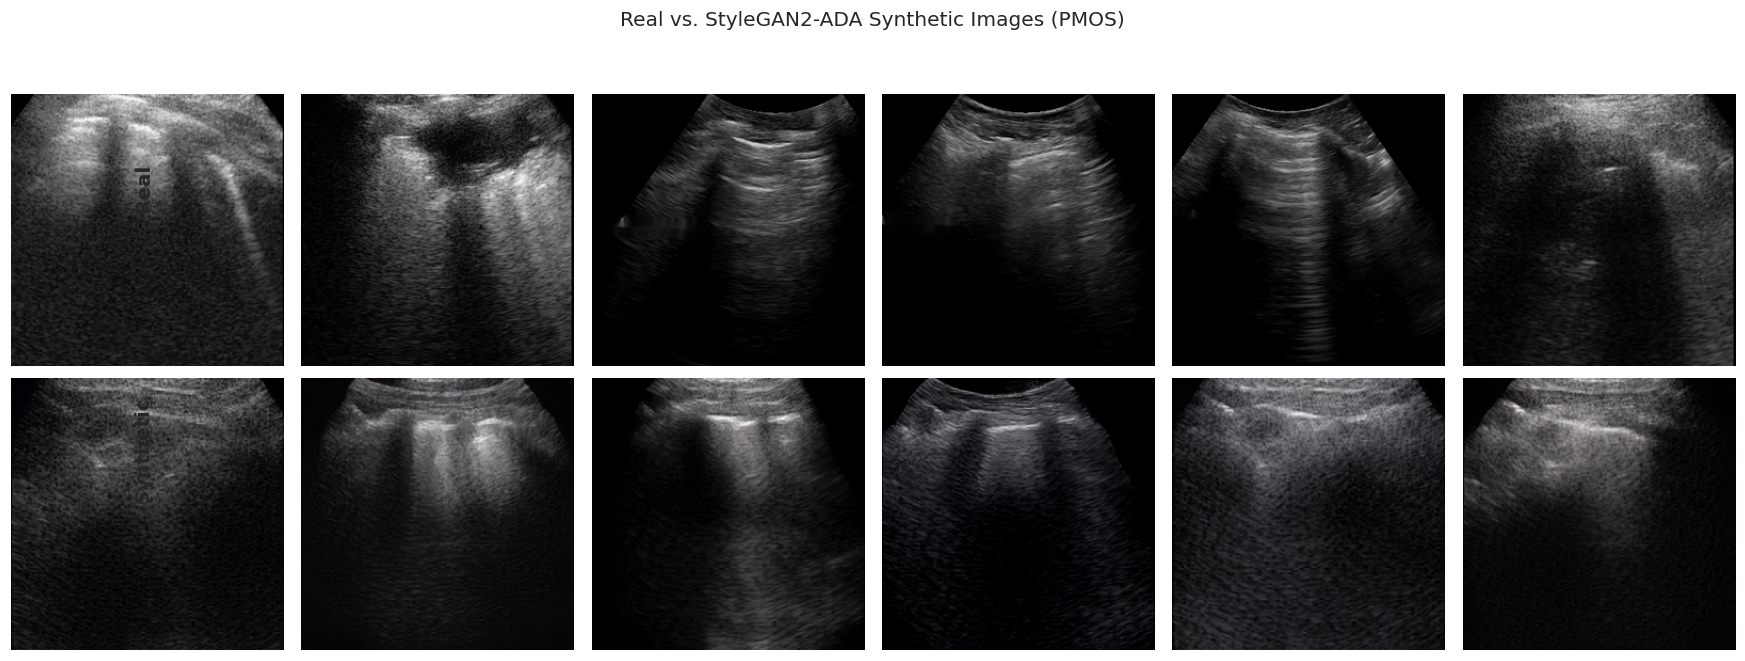

In [63]:
# --- 18.1 Original vs Synthetic grid ------------------------------------
real_sample = random.sample(real_paths, 6)
synth_sample = random.sample(sorted(glob.glob(f"{PATHS['generated']}/*.png")), 6)

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, p in zip(axes[0], real_sample):
    ax.imshow(Image.open(p)); ax.axis("off")
for ax, p in zip(axes[1], synth_sample):
    ax.imshow(Image.open(p)); ax.axis("off")
axes[0, 0].set_ylabel("Real", fontsize=13)
axes[1, 0].set_ylabel("Synthetic", fontsize=13)
fig.text(0.08, 0.72, "Real", rotation=90, fontsize=13, fontweight="bold")
fig.text(0.08, 0.28, "Synthetic", rotation=90, fontsize=13, fontweight="bold")
plt.suptitle("Real vs. StyleGAN2-ADA Synthetic Images (PMOS)", y=1.02)
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/real_vs_synthetic.png", bbox_inches="tight")
plt.savefig(f"{PATHS['figures']}/real_vs_synthetic.pdf", bbox_inches="tight")
plt.show()


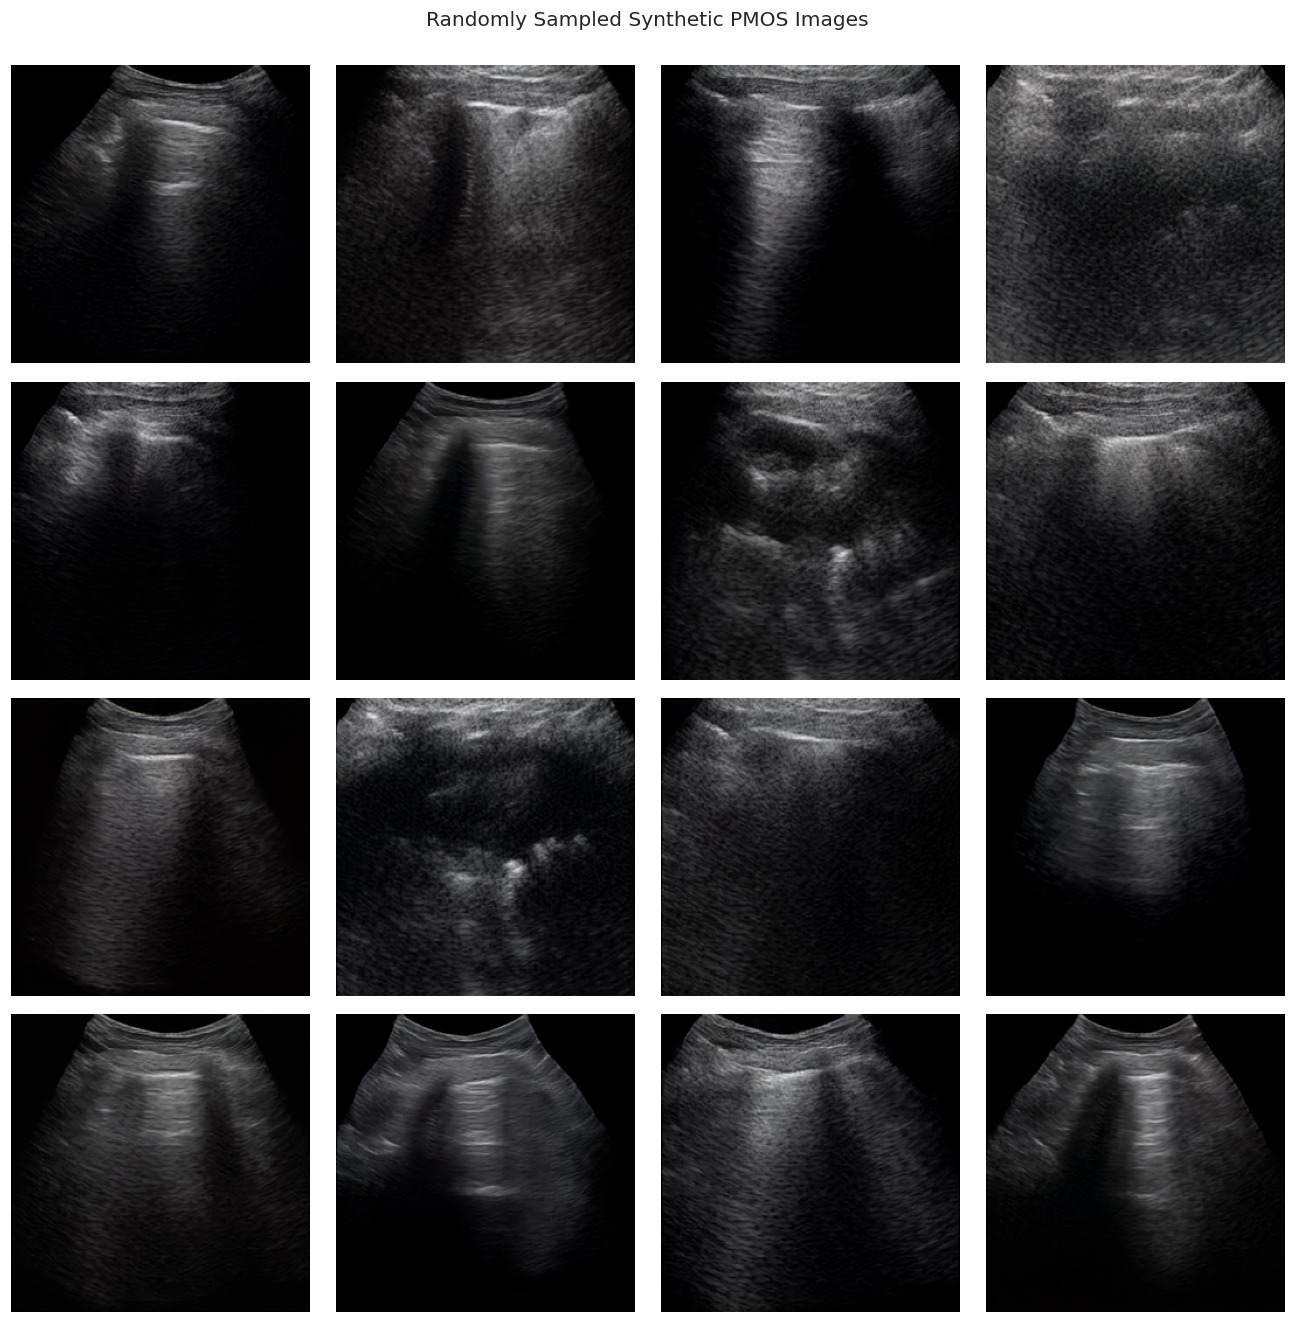

In [64]:
# --- 18.2 Random generated gallery ---------------------------------------
gallery_sample = random.sample(sorted(glob.glob(f"{PATHS['generated']}/*.png")), 16)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, p in zip(axes.flatten(), gallery_sample):
    ax.imshow(Image.open(p)); ax.axis("off")
plt.suptitle("Randomly Sampled Synthetic PMOS Images", y=1.0)
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/synthetic_gallery.png", bbox_inches="tight")
plt.show()


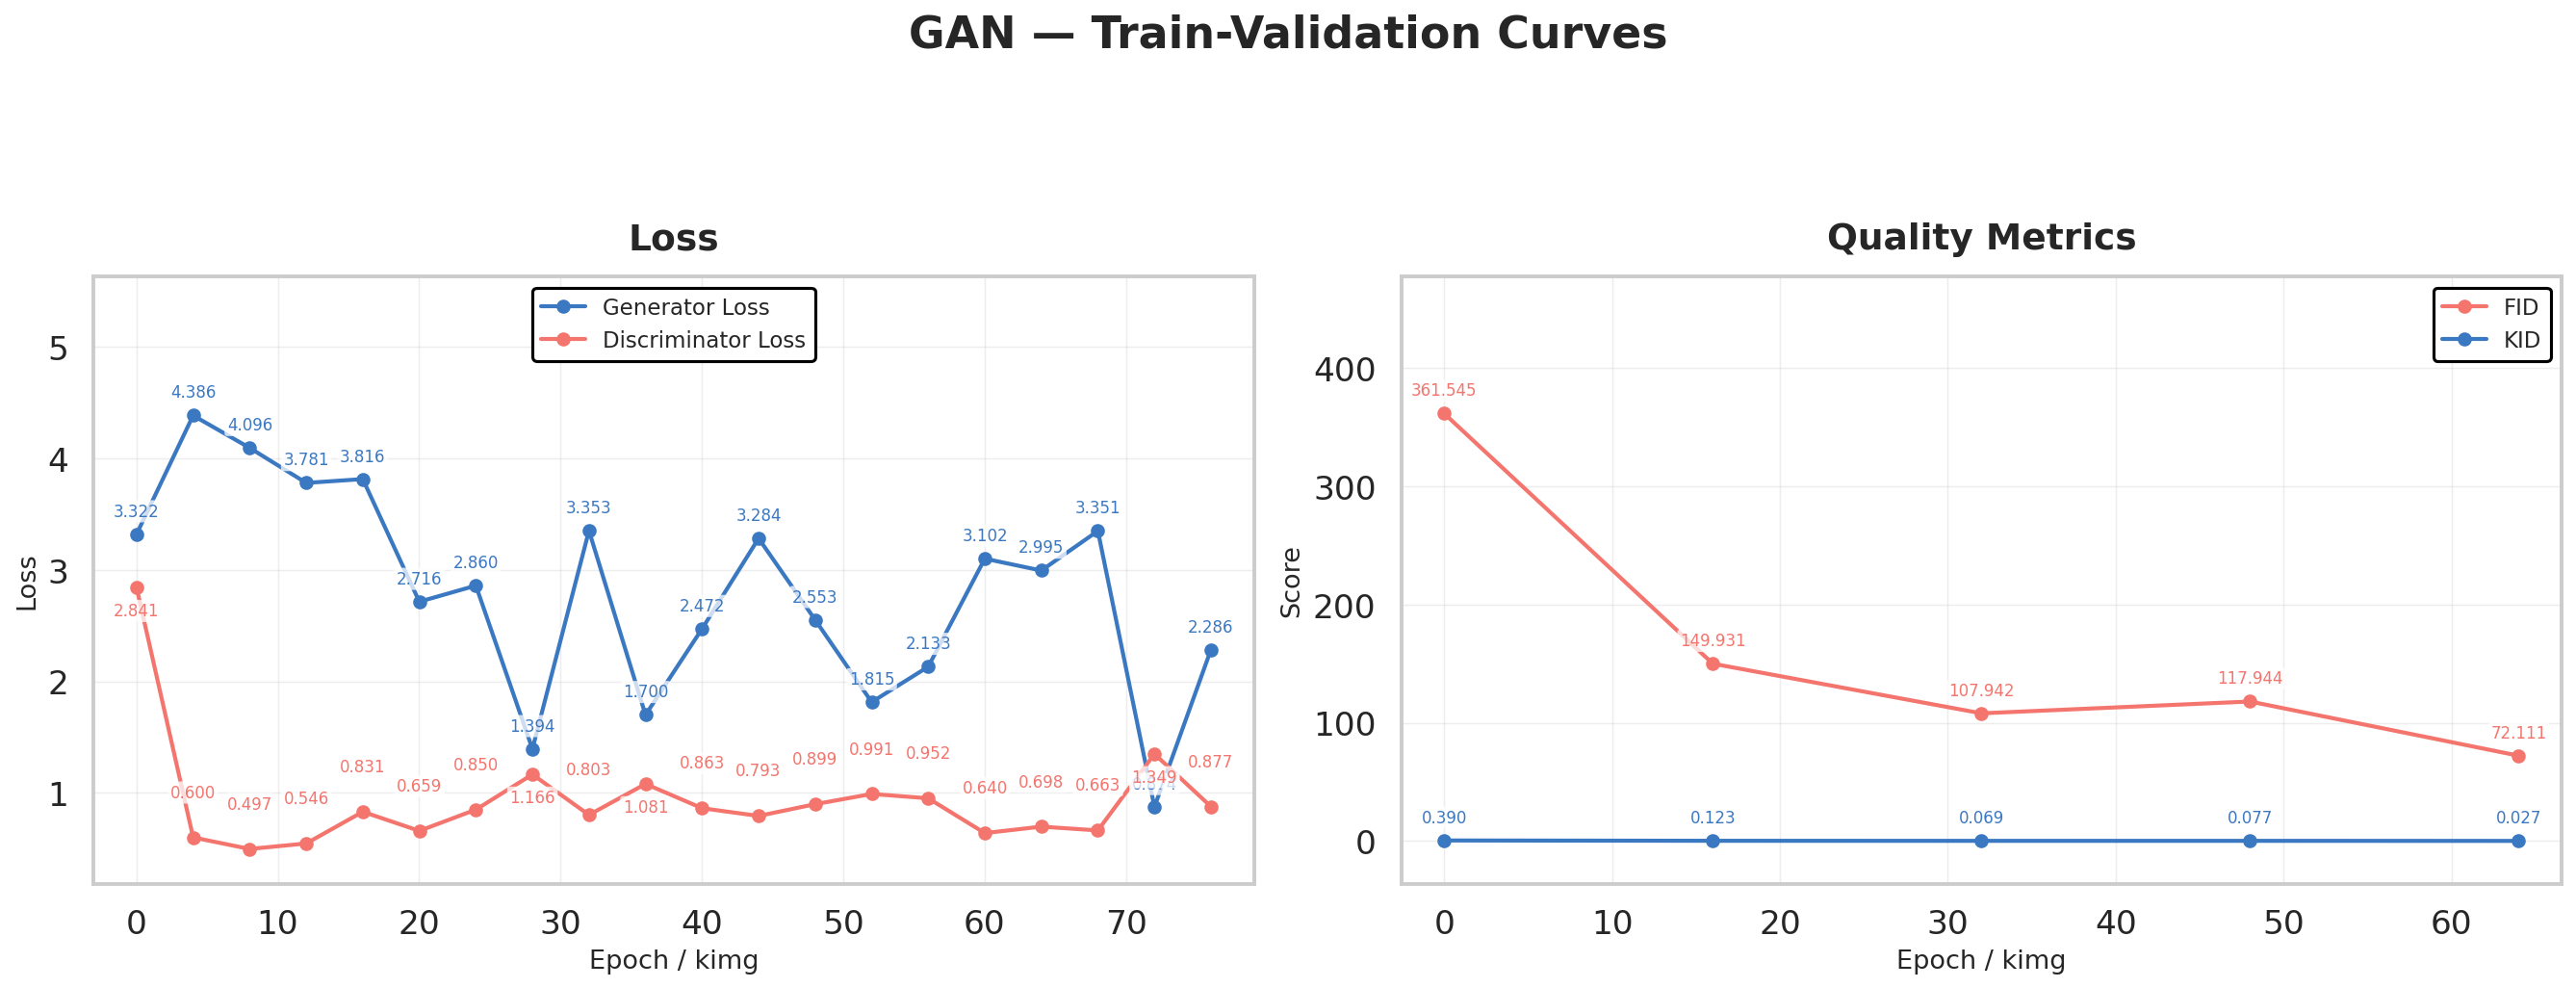

In [65]:
# --- 18.X GAN Training Curves (Loss + FID) — paper-ready, no overlap -------
def load_training_stats(run_dir):
    stats_path = os.path.join(run_dir, "stats.jsonl")
    rows = []
    if not os.path.isfile(stats_path):
        return pd.DataFrame()
    with open(stats_path) as f:
        for line in f:
            try:
                d = json.loads(line)
            except json.JSONDecodeError:
                continue
            row = {"kimg": d.get("Progress/kimg", {}).get("mean")}
            for key in ["Loss/G/loss", "Loss/D/loss"]:
                if key in d:
                    row[key] = d[key].get("mean")
            rows.append(row)
    return pd.DataFrame(rows).dropna(subset=["kimg"])

df_loss = load_training_stats(RUN_DIR)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
})

color_g   = "#3B78C2"   # blue
color_d   = "#F4756E"   # salmon-red
color_fid = "#F4756E"   # salmon-red
color_kid = "#3B78C2"   # blue

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), dpi=150)

label_bbox = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75)

# --- smart label helper: flips a label up/down so it never clips the top
#     of the axes or crowds the x-axis tick labels at the bottom -----------
def label_points(ax, x, y, color, base_offset, step=1, fmt="{:.3f}"):
    ymin, ymax = ax.get_ylim()
    rng = ymax - ymin
    xs = list(x)[::step]
    ys = list(y)[::step]
    for xi, yi in zip(xs, ys):
        offset = base_offset
        frac = (yi - ymin) / rng if rng else 0.5
        if offset > 0 and frac > 0.85:      # too close to top -> flip down
            offset = -abs(offset) - 6
        elif offset < 0 and frac < 0.15:    # too close to bottom -> flip up
            offset = abs(offset) + 6
        ax.annotate(fmt.format(yi), (xi, yi),
                    textcoords="offset points", xytext=(0, offset),
                    ha="center", fontsize=8, color=color, bbox=label_bbox, zorder=5)

# ================= Left panel: Loss =================
if not df_loss.empty and "Loss/G/loss" in df_loss.columns:
    ax1.plot(df_loss["kimg"], df_loss["Loss/G/loss"],
             marker="o", markersize=6, linewidth=2,
             color=color_g, label="Generator Loss", zorder=3)
    ax1.plot(df_loss["kimg"], df_loss["Loss/D/loss"],
             marker="o", markersize=6, linewidth=2,
             color=color_d, label="Discriminator Loss", zorder=3)

    # extra headroom/footroom so labels + the highest peak never touch the
    # suptitle or the x-axis
    y_all = pd.concat([df_loss["Loss/G/loss"], df_loss["Loss/D/loss"]])
    y_min, y_max = y_all.min(), y_all.max()
    pad = (y_max - y_min) * 0.20
    ax1.set_ylim(y_min - pad * 0.4, y_max + pad * 1.6)

    x_min, x_max = df_loss["kimg"].min(), df_loss["kimg"].max()
    x_pad = (x_max - x_min) * 0.04
    ax1.set_xlim(x_min - x_pad, x_max + x_pad)

    n = len(df_loss)
    step = max(1, n // 20)
    label_points(ax1, df_loss["kimg"], df_loss["Loss/G/loss"], color_g, base_offset=9, step=step)
    label_points(ax1, df_loss["kimg"], df_loss["Loss/D/loss"], color_d, base_offset=-14, step=step)
else:
    ax1.text(0.5, 0.5, "stats.jsonl not found /\nmissing loss keys",
              ha="center", va="center", transform=ax1.transAxes, fontsize=12, color="gray")

ax1.set_title("Loss", fontsize=18, fontweight="bold", pad=14)
ax1.set_xlabel("Epoch / kimg", fontsize=13)
ax1.set_ylabel("Loss", fontsize=13)
ax1.grid(True, linestyle="-", linewidth=0.7, alpha=0.35, zorder=0)
ax1.set_axisbelow(True)
ax1.legend(loc="upper center", frameon=True, framealpha=1, edgecolor="black", fontsize=11)

# ================= Right panel: FID/KID (quality proxy) =================
ax2.plot(df_metrics["kimg"], df_metrics["fid"],
         marker="o", markersize=6, linewidth=2,
         color=color_fid, label="FID", zorder=3)
ax2.plot(df_metrics["kimg"], df_metrics["kid_mean"],
         marker="o", markersize=6, linewidth=2,
         color=color_kid, label="KID", zorder=3)

y_all2 = pd.concat([df_metrics["fid"], df_metrics["kid_mean"]])
y_min2, y_max2 = y_all2.min(), y_all2.max()
pad2 = (y_max2 - y_min2) * 0.20
ax2.set_ylim(min(0, y_min2 - pad2 * 0.5), y_max2 + pad2 * 1.6)

x_min2, x_max2 = df_metrics["kimg"].min(), df_metrics["kimg"].max()
x_pad2 = (x_max2 - x_min2) * 0.04
ax2.set_xlim(x_min2 - x_pad2, x_max2 + x_pad2)

# both labels placed ABOVE their own line (FID sits high, KID sits near
# zero) so neither one collides with the x-axis tick labels below
label_points(ax2, df_metrics["kimg"], df_metrics["fid"], color_fid, base_offset=9, fmt="{:.3f}")
label_points(ax2, df_metrics["kimg"], df_metrics["kid_mean"], color_kid, base_offset=9, fmt="{:.3f}")

ax2.set_title("Quality Metrics", fontsize=18, fontweight="bold", pad=14)
ax2.set_xlabel("Epoch / kimg", fontsize=13)
ax2.set_ylabel("Score", fontsize=13)
ax2.grid(True, linestyle="-", linewidth=0.7, alpha=0.35, zorder=0)
ax2.set_axisbelow(True)
ax2.legend(loc="upper right", frameon=True, framealpha=1, edgecolor="black", fontsize=11)

fig.suptitle("GAN — Train-Validation Curves", fontsize=22, fontweight="bold", y=1.05)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(f"{PATHS['figures']}/gan_training_curves.png", bbox_inches="tight", dpi=300)
plt.savefig(f"{PATHS['figures']}/gan_training_curves.pdf", bbox_inches="tight")
plt.show()

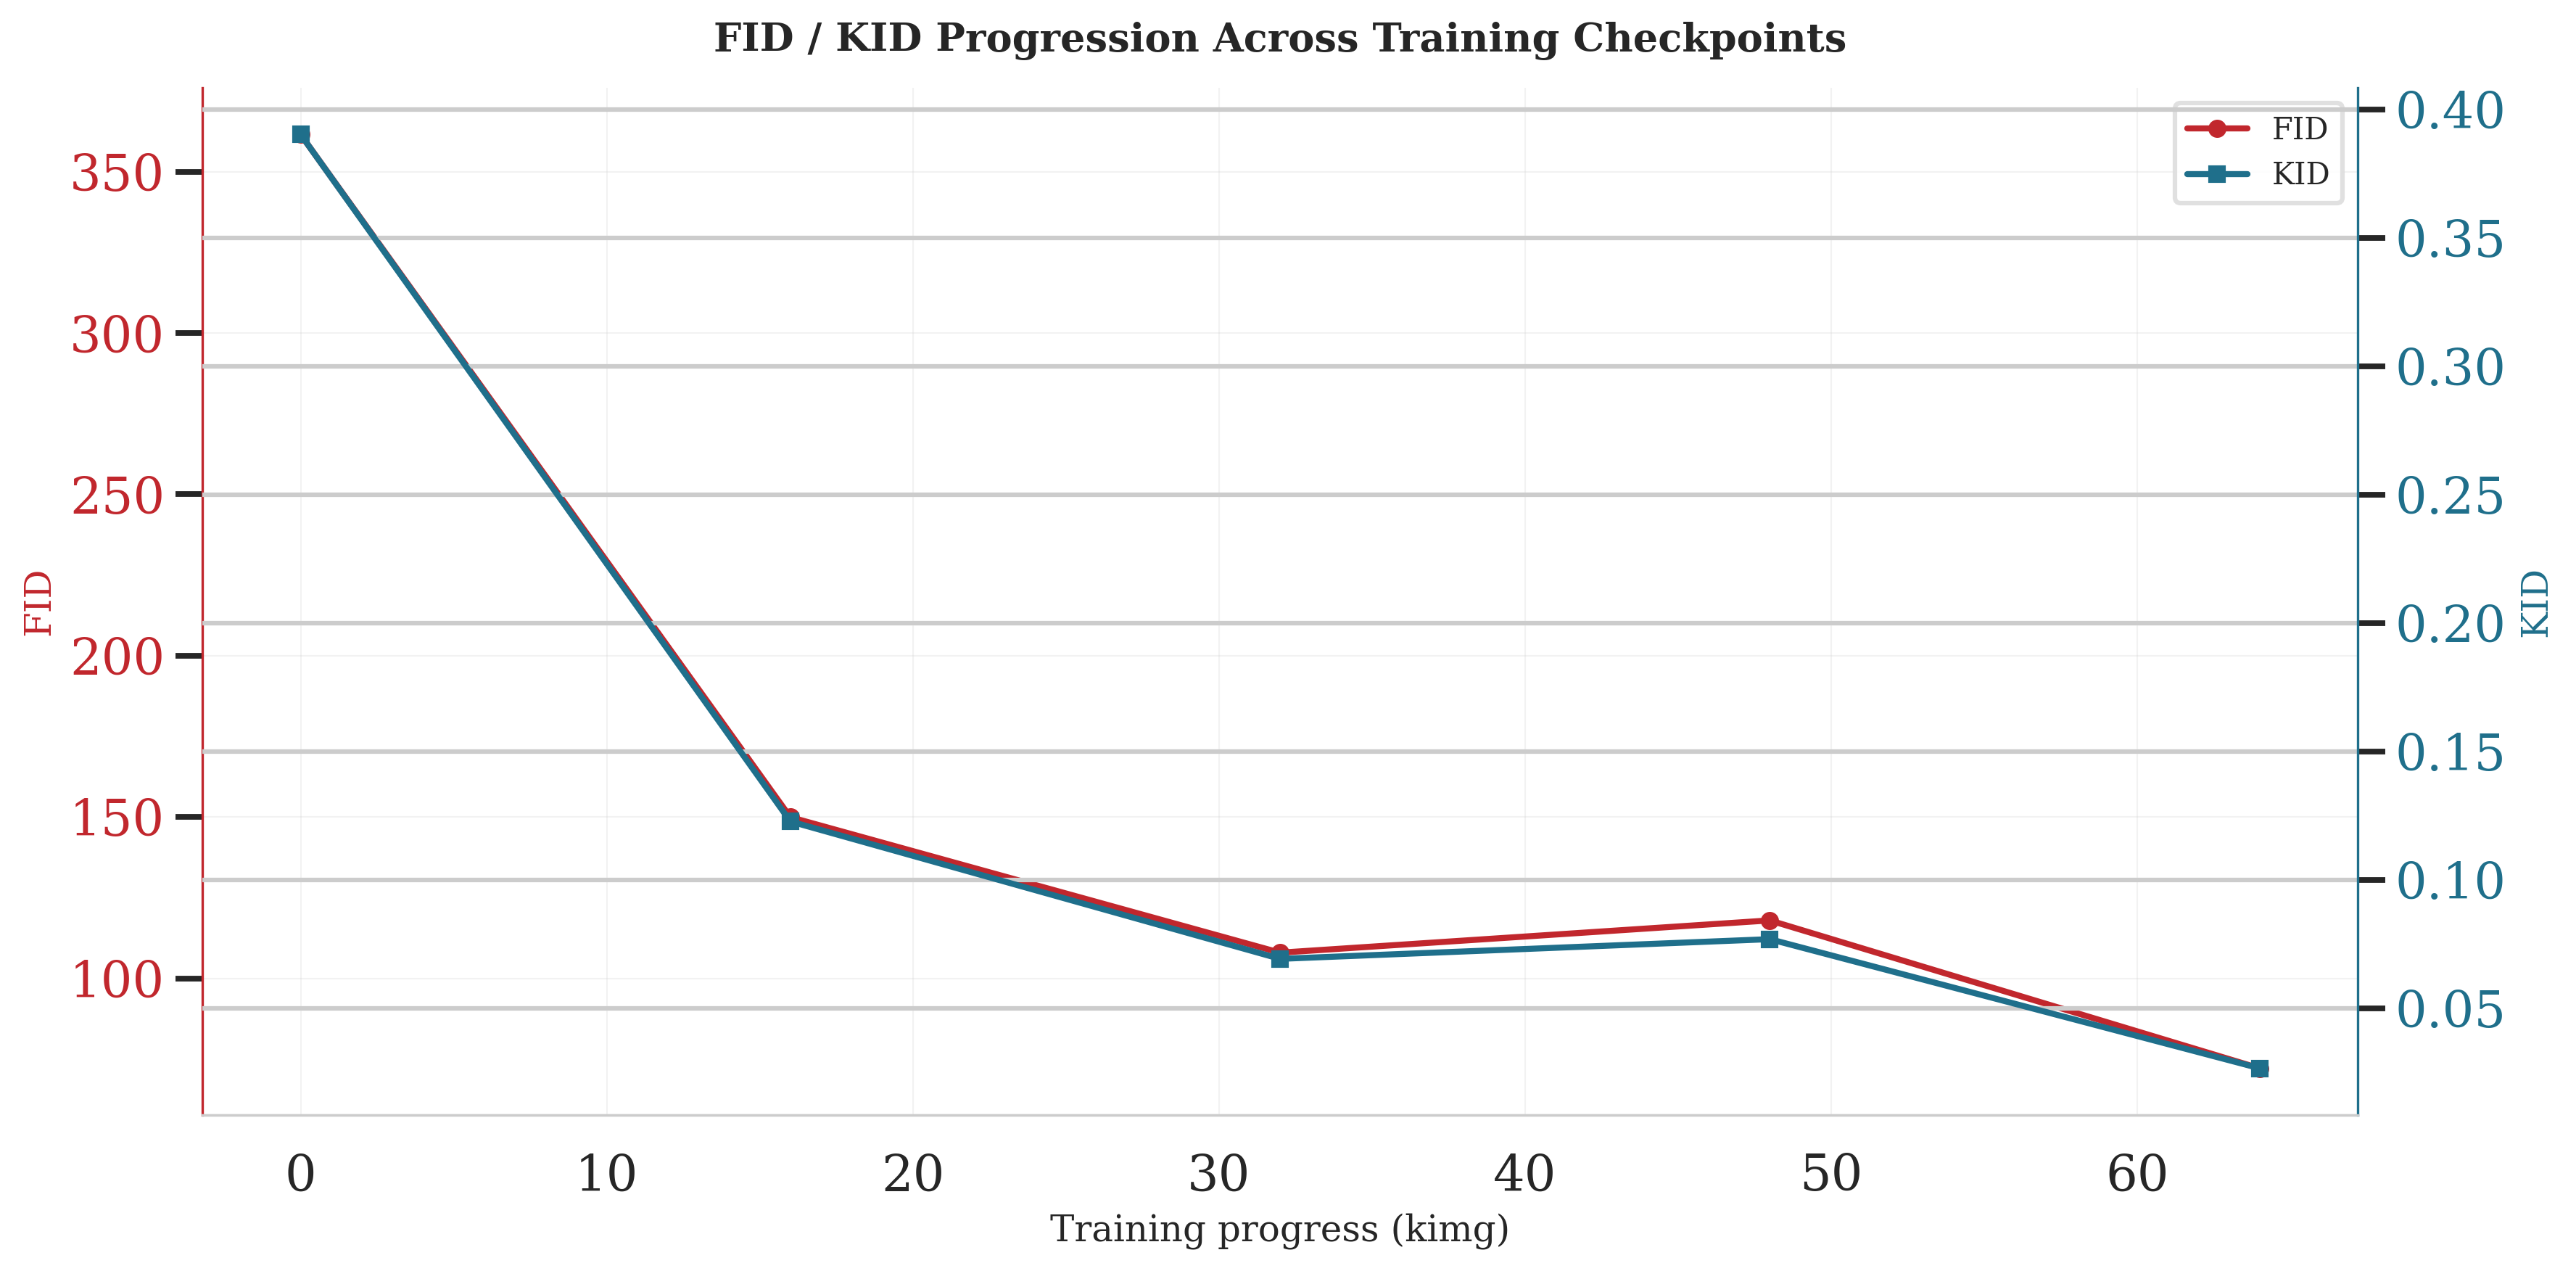

In [66]:
# --- 18.3 FID progression across checkpoints (modernized, Q1-paper style) ---
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 0.8,
    "mathtext.fontset": "cm",
})

color_fid = "#C1272D"   # deep crimson
color_kid = "#1f6f8b"   # muted steel-teal

fig, ax1 = plt.subplots(figsize=(12, 6), dpi=300)

# FID curve
ax1.plot(df_metrics["kimg"], df_metrics["fid"],
          marker="o", markersize=5, linewidth=2,
          color=color_fid, label="FID", zorder=3)
ax1.set_xlabel("Training progress (kimg)", fontsize=12)
ax1.set_ylabel("FID", color=color_fid, fontsize=12)
ax1.tick_params(axis="y", labelcolor=color_fid)

# KID curve on secondary axis
ax2 = ax1.twinx()
ax2.plot(df_metrics["kimg"], df_metrics["kid_mean"],
          marker="s", markersize=5, linewidth=2,
          color=color_kid, label="KID", zorder=3)
ax2.set_ylabel("KID", color=color_kid, fontsize=12)
ax2.tick_params(axis="y", labelcolor=color_kid)

# Clean spines
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
ax1.spines["left"].set_color(color_fid)
ax2.spines["right"].set_color(color_kid)
ax1.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)

# Subtle grid (behind everything)
ax1.grid(True, which="major", axis="both", linestyle="-",
          linewidth=0.5, alpha=0.25, zorder=0)
ax1.set_axisbelow(True)

# Nicely spaced ticks
ax1.xaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=8))

# Combined legend, cleanly framed
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
legend = ax1.legend(lines1 + lines2, labels1 + labels2,
                     loc="upper right", frameon=True, framealpha=0.9,
                     edgecolor="#dddddd", fontsize=10)

plt.title("FID / KID Progression Across Training Checkpoints",
          fontsize=13, fontweight="bold", pad=12)

plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/fid_kid_curve.png", bbox_inches="tight", dpi=300)
plt.savefig(f"{PATHS['figures']}/fid_kid_curve.pdf", bbox_inches="tight")  # vector version for LaTeX
plt.show()

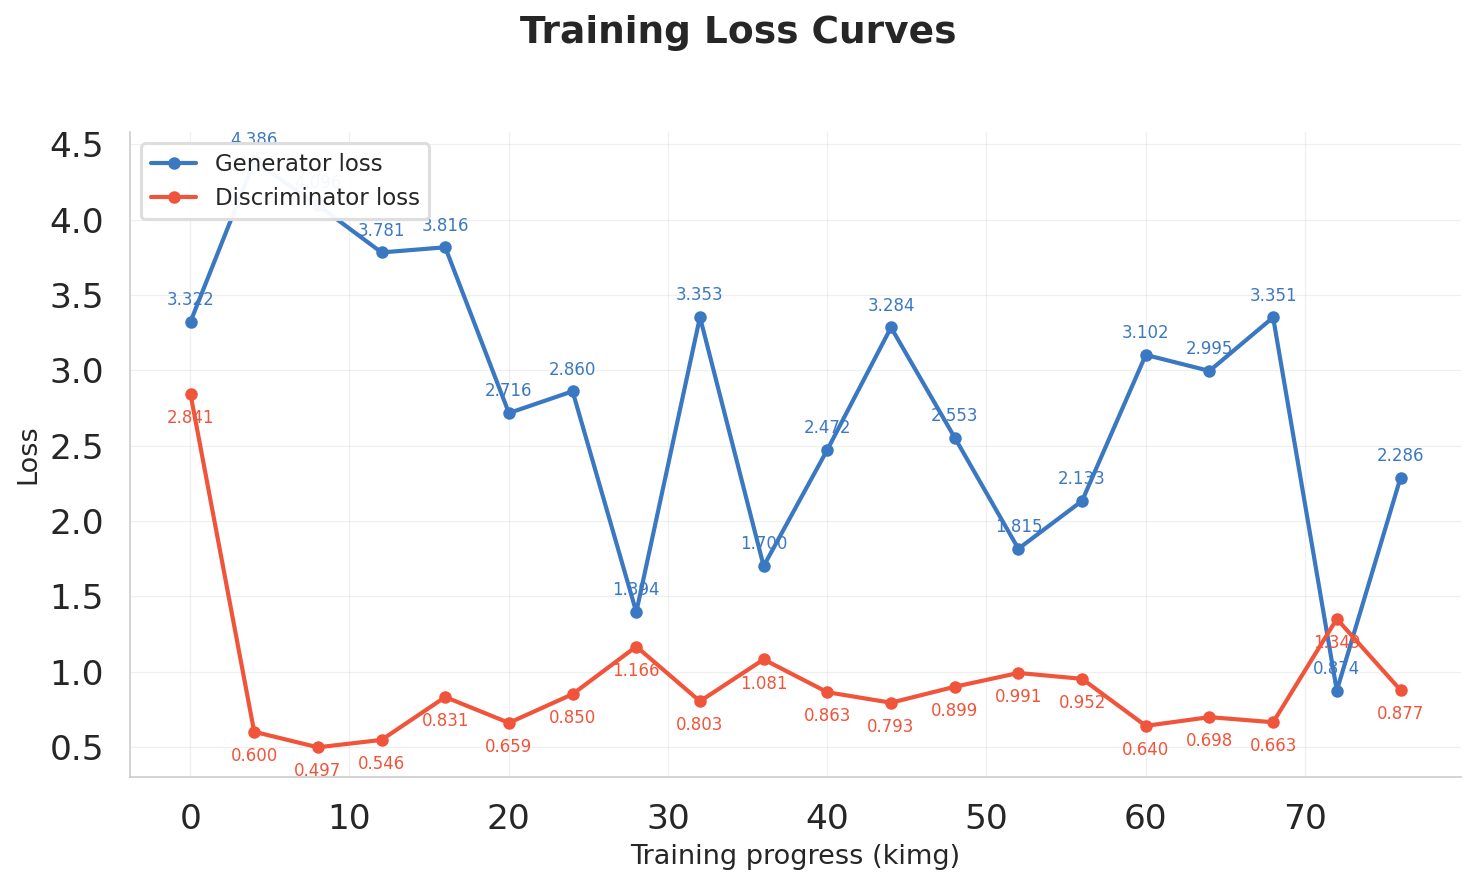

In [67]:
# --- 18.4 Training loss curves (parsed from stats.jsonl) ------------------
def load_training_stats(run_dir):
    stats_path = os.path.join(run_dir, "stats.jsonl")
    rows = []
    if not os.path.isfile(stats_path):
        return pd.DataFrame()
    with open(stats_path) as f:
        for line in f:
            try:
                d = json.loads(line)
            except json.JSONDecodeError:
                continue
            row = {"kimg": d.get("Progress/kimg", {}).get("mean")}
            for key in ["Loss/G/loss", "Loss/D/loss"]:
                if key in d:
                    row[key] = d[key].get("mean")
            rows.append(row)
    return pd.DataFrame(rows).dropna(subset=["kimg"])

df_loss = load_training_stats(RUN_DIR)

if not df_loss.empty and "Loss/G/loss" in df_loss.columns:

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.size": 12,
    })

    color_g = "#3B78C2"   # blue
    color_d = "#F0553B"   # red-orange

    fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

    # --- Generator loss ---
    ax.plot(df_loss["kimg"], df_loss["Loss/G/loss"],
            marker="o", markersize=5, linewidth=2,
            color=color_g, label="Generator loss", zorder=3)

    # --- Discriminator loss ---
    ax.plot(df_loss["kimg"], df_loss["Loss/D/loss"],
            marker="o", markersize=5, linewidth=2,
            color=color_d, label="Discriminator loss", zorder=3)

    # --- Value labels (skip some points if too dense) ---
    n_points = len(df_loss)
    step = max(1, n_points // 20)   # show ~20 labels max to avoid clutter
    for i in range(0, n_points, step):
        x = df_loss["kimg"].iloc[i]
        yg = df_loss["Loss/G/loss"].iloc[i]
        yd = df_loss["Loss/D/loss"].iloc[i]
        ax.annotate(f"{yg:.3f}", (x, yg), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=8, color=color_g)
        ax.annotate(f"{yd:.3f}", (x, yd), textcoords="offset points",
                    xytext=(0, -14), ha="center", fontsize=8, color=color_d)

    # --- Axis labels / title ---
    ax.set_xlabel("Training progress (kimg)", fontsize=13)
    ax.set_ylabel("Loss", fontsize=13)
    fig.suptitle("Training Loss Curves", fontsize=18, fontweight="bold", y=0.98)

    # --- Grid & spines ---
    ax.grid(True, linestyle="-", linewidth=0.6, alpha=0.3, zorder=0)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    # --- Legend ---
    ax.legend(loc="upper left", frameon=True, framealpha=0.95,
               edgecolor="#dddddd", fontsize=11)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(f"{PATHS['figures']}/loss_curve.png", bbox_inches="tight", dpi=300)
    plt.savefig(f"{PATHS['figures']}/loss_curve.pdf", bbox_inches="tight")
    plt.show()
else:
    print("stats.jsonl did not contain the expected loss keys — skipping loss curve "
          "(training log format may differ slightly across repo versions).")

In [68]:
# --- 18.5 Compile and save final results ----------------------------------
summary = {
    "generated_at": datetime.now().isoformat(),
    "dataset": {
        "root": DATASET_ROOT,
        "n_images_total": int(summary_stats["total_images"]),
        "class_counts": summary_stats["classes"],
        "resolution": f"{IMG_SIZE}x{IMG_SIZE}",
        "conditioning": "unconditional (PMOS + NON PMOS combined)",
    },
    "training": {
        "config": TRAIN_CONFIG,
        "max_train_hours": MAX_TRAIN_HOURS,
        "run_dir": RUN_DIR,
        "n_checkpoints_saved": len(snapshots),
        "n_checkpoints_evaluated": len(checkpoint_names),
    },
    "best_checkpoint": {
        "name": best_checkpoint_name,
        "fid": float(best_row["fid"]),
        "kid_mean": float(best_row["kid_mean"]),
        "kid_std": float(best_row["kid_std"]),
        "lpips_diversity": (
            float(best_row["lpips_diversity"])
            if "lpips_diversity" in best_row and not pd.isna(best_row["lpips_diversity"])
            else None
        ),
    },
    "export": {
        "num_final_images": n_done,
        "truncation_psi": TRUNCATION_PSI,
        "output_dir": PATHS["generated"],
    },
}

with open(f"{PATHS['results']}/summary.json", "w") as f:
    json.dump(summary, f, indent=2)

df_metrics.to_csv(f"{PATHS['results']}/checkpoint_metrics.csv", index=False)

print(json.dumps(summary, indent=2))


{
  "generated_at": "2026-08-29T12:25:15.842450",
  "dataset": {
    "root": "/kaggle/input/datasets/shuvosingh/lus-cnn-hybrid/LUS Images for Automated AI-based Lung Disease Classification",
    "n_images_total": 1062,
    "class_counts": {
      "other": 362,
      "healthy": 362,
      "covid": 338
    },
    "resolution": "256x256",
    "conditioning": "unconditional (PMOS + NON PMOS combined)"
  },
  "training": {
    "config": {
      "outdir": "/kaggle/working/training-runs",
      "data": "/kaggle/working/data/pmos_256.zip",
      "gpus": 1,
      "cfg": "auto",
      "resume": "/kaggle/working/pretrained/ffhq256.pkl",
      "aug": "ada",
      "mirror": 1,
      "snap": 4,
      "metrics": "none",
      "workers": 4,
      "kimg": 3000,
      "seed": 42
    },
    "max_train_hours": 5.0,
    "run_dir": "/kaggle/working/training-runs/00000-pmos_256-mirror-auto1-kimg3000-ada-resumecustom",
    "n_checkpoints_saved": 5,
    "n_checkpoints_evaluated": 5
  },
  "best_checkpoint": {


In [69]:
# --- 18.6 Zip key deliverables for download --------------------------------
zip_base = f"{WORK_DIR}/pmos_stylegan2ada_results"
shutil.make_archive(zip_base, "zip", PATHS["results"])
print(f"Results archive: {zip_base}.zip")

print("\nFinal output folders:")
for name in ["generated", "metrics", "figures", "results"]:
    p = PATHS[name]
    n_files = sum(len(files) for _, _, files in os.walk(p))
    print(f"  {name:12s} -> {p}  ({n_files} files)")


Results archive: /kaggle/working/pmos_stylegan2ada_results.zip

Final output folders:
  generated    -> /kaggle/working/generated  (4000 files)
  metrics      -> /kaggle/working/metrics  (1501 files)
  figures      -> /kaggle/working/figures  (15 files)
  results      -> /kaggle/working/results  (3 files)


In [70]:
import shutil
from IPython.display import FileLink

zip_path = shutil.make_archive(f"{WORK_DIR}/synthetic_images", "zip", PATHS["generated"])
print(f"Zipped: {zip_path}")
FileLink(zip_path.replace("/kaggle/working/", ""))

Zipped: /kaggle/working/synthetic_images.zip


/kaggle/working/synthetic_images.zip

In [71]:
# --- 19. Classify Synthetic Images by Class & Zip --------------------------
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

# --- 19.1 Build labeled dataset from processed_256 filenames ---------------
# filenames look like: 00001_PMOS.png / 00002_NON-PMOS.png (class in filename)
processed_files = sorted(glob.glob(f"{PATHS['processed']}/*.png"))
class_names = sorted(df_clean["class"].unique().tolist())
class_to_idx = {c: i for i, c in enumerate(class_names)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
print("Classes:", class_to_idx)

def filename_to_class(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    suffix = stem.split("_", 1)[1].replace("-", " ")
    # match against known class names (case-insensitive, whitespace tolerant)
    for c in class_names:
        if c.strip().lower() == suffix.strip().lower():
            return c
    raise ValueError(f"Could not map filename '{fname}' to a known class.")

labels = [class_to_idx[filename_to_class(f)] for f in processed_files]

class ImgDataset(Dataset):
    def __init__(self, paths, labels=None, train=True):
        self.paths = paths
        self.labels = labels
        self.tf = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.RandomHorizontalFlip() if train else transforms.Lambda(lambda x: x),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        img = self.tf(img)
        if self.labels is not None:
            return img, self.labels[idx]
        return img, self.paths[idx]

# --- 19.2 Train/val split -----------------------------------------------
idx_all = np.arange(len(processed_files))
np.random.RandomState(SEED).shuffle(idx_all)
n_val = max(1, int(0.15 * len(idx_all)))
val_idx, train_idx = idx_all[:n_val], idx_all[n_val:]

train_paths = [processed_files[i] for i in train_idx]
train_labels = [labels[i] for i in train_idx]
val_paths = [processed_files[i] for i in val_idx]
val_labels = [labels[i] for i in val_idx]

train_ds = ImgDataset(train_paths, train_labels, train=True)
val_ds = ImgDataset(val_paths, val_labels, train=False)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

# --- 19.3 Quick transfer-learning classifier (ResNet18) --------------------
clf = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
clf.fc = nn.Linear(clf.fc.in_features, len(class_names))
clf = clf.to(DEVICE)

optimizer = optim.Adam(clf.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

N_EPOCHS_CLF = 8
for epoch in range(N_EPOCHS_CLF):
    clf.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        optimizer.zero_grad()
        out = clf(imgs)
        loss = criterion(out, lbls)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == lbls).sum().item()
        total += imgs.size(0)

    clf.eval()
    v_correct, v_total = 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            out = clf(imgs)
            v_correct += (out.argmax(1) == lbls).sum().item()
            v_total += imgs.size(0)

    print(f"Epoch {epoch+1}/{N_EPOCHS_CLF} | "
          f"train_loss={total_loss/total:.4f} train_acc={correct/total:.3f} "
          f"| val_acc={v_correct/v_total:.3f}")

# --- 19.4 Predict class for every synthetic image ---------------------------
synth_paths = sorted(glob.glob(f"{PATHS['generated']}/*.png"))
synth_ds = ImgDataset(synth_paths, labels=None, train=False)
synth_loader = DataLoader(synth_ds, batch_size=32, shuffle=False, num_workers=2)

clf.eval()
BY_CLASS_DIR = f"{WORK_DIR}/synthetic_by_class"
shutil.rmtree(BY_CLASS_DIR, ignore_errors=True)
for c in class_names:
    os.makedirs(f"{BY_CLASS_DIR}/{c.replace(' ', '-')}", exist_ok=True)

with torch.no_grad():
    for imgs, paths in tqdm(synth_loader, desc="Classifying synthetic images"):
        imgs = imgs.to(DEVICE)
        preds = clf(imgs).argmax(1).cpu().numpy()
        for p, pred in zip(paths, preds):
            cls_name = idx_to_class[pred].replace(" ", "-")
            dest = f"{BY_CLASS_DIR}/{cls_name}/{os.path.basename(p)}"
            shutil.copy2(p, dest)

for c in class_names:
    n = len(os.listdir(f"{BY_CLASS_DIR}/{c.replace(' ', '-')}"))
    print(f"{c}: {n} synthetic images")

# --- 19.5 Zip class-organized synthetic images ------------------------------
by_class_zip = shutil.make_archive(f"{WORK_DIR}/synthetic_images_by_class", "zip", BY_CLASS_DIR)
print(f"\nZipped: {by_class_zip}")

from IPython.display import FileLink
FileLink(by_class_zip.replace("/kaggle/working/", ""))

Classes: {'covid': 0, 'healthy': 1, 'other': 2}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s] 


Epoch 1/8 | train_loss=0.5373 train_acc=0.785 | val_acc=0.862
Epoch 2/8 | train_loss=0.2973 train_acc=0.883 | val_acc=0.824
Epoch 3/8 | train_loss=0.2023 train_acc=0.924 | val_acc=0.868
Epoch 4/8 | train_loss=0.1312 train_acc=0.952 | val_acc=0.874
Epoch 5/8 | train_loss=0.1221 train_acc=0.957 | val_acc=0.887
Epoch 6/8 | train_loss=0.1213 train_acc=0.957 | val_acc=0.881
Epoch 7/8 | train_loss=0.0959 train_acc=0.967 | val_acc=0.868
Epoch 8/8 | train_loss=0.0996 train_acc=0.971 | val_acc=0.855


Classifying synthetic images:   0%|          | 0/125 [00:00<?, ?it/s]

covid: 1786 synthetic images
healthy: 1377 synthetic images
other: 837 synthetic images

Zipped: /kaggle/working/synthetic_images_by_class.zip


/kaggle/working/synthetic_images_by_class.zip

In [72]:
# --- 19. Additional GAN Evaluation Metrics ----------------------------------
!pip install prdc torchmetrics[image] --quiet

import torch
from torchmetrics.image.inception import InceptionScore
from torchmetrics.image.fid import FrechetInceptionDistance
from prdc import compute_prdc
from scipy import linalg
from sklearn.manifold import TSNE

In [73]:
def images_to_uint8_tensor(image_paths, size=299):
    arrs = []
    for p in image_paths:
        im = Image.open(p).convert("RGB").resize((size, size))
        arrs.append(np.asarray(im))
    arr = np.stack(arrs)
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()

synth_paths_all = sorted(glob.glob(f"{PATHS['generated']}/*.png"))

is_metric = InceptionScore(normalize=False).to(DEVICE)
batch_size = 32
for i in tqdm(range(0, len(synth_paths_all), batch_size), desc="Computing Inception Score"):
    batch_paths = synth_paths_all[i:i+batch_size]
    imgs = images_to_uint8_tensor(batch_paths).to(DEVICE)
    is_metric.update(imgs)

is_mean, is_std = is_metric.compute()
print(f"Inception Score: {is_mean.item():.3f} ± {is_std.item():.3f}")

Computing Inception Score:   0%|          | 0/125 [00:00<?, ?it/s]

Inception Score: 2.228 ± 0.062


In [74]:
from torchvision.models import inception_v3, Inception_V3_Weights

feat_extractor = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1, aux_logits=True)
feat_extractor.fc = torch.nn.Identity()   # use 2048-d pool features
feat_extractor = feat_extractor.to(DEVICE).eval()

feat_tf = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

@torch.no_grad()
def extract_features(paths, batch_size=32):
    feats = []
    for i in tqdm(range(0, len(paths), batch_size), desc="Extracting features"):
        batch = paths[i:i+batch_size]
        imgs = torch.stack([feat_tf(Image.open(p).convert("RGB")) for p in batch]).to(DEVICE)
        f = feat_extractor(imgs)
        feats.append(f.cpu().numpy())
    return np.concatenate(feats, axis=0)

real_feats = extract_features(real_paths)
synth_feats = extract_features(synth_paths_all)
print("Real features:", real_feats.shape, "| Synthetic features:", synth_feats.shape)

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 214MB/s]  


Extracting features:   0%|          | 0/34 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/125 [00:00<?, ?it/s]

Real features: (1062, 2048) | Synthetic features: (4000, 2048)


In [ ]:
prdc_results = compute_prdc(
    real_features=real_feats,
    fake_features=synth_feats,
    nearest_k=5,
)
print("Precision (fidelity)         :", round(prdc_results["precision"], 4))
print("Recall    (diversity)        :", round(prdc_results["recall"], 4))
print("Density   (robust fidelity)  :", round(prdc_results["density"], 4))
print("Coverage  (robust diversity) :", round(prdc_results["coverage"], 4))

with open(f"{PATHS['results']}/precision_recall_density_coverage.json", "w") as f:
    json.dump(prdc_results, f, indent=2)

In [ ]:
from sklearn.neighbors import NearestNeighbors

nn_model = NearestNeighbors(n_neighbors=1, metric="euclidean").fit(real_feats)
dists, idxs = nn_model.kneighbors(synth_feats)

df_memo = pd.DataFrame({
    "synthetic_path": synth_paths_all,
    "nearest_real_path": [real_paths[i] for i in idxs.flatten()],
    "feature_distance": dists.flatten(),
})
df_memo = df_memo.sort_values("feature_distance").reset_index(drop=True)
df_memo.to_csv(f"{PATHS['results']}/memorization_nn_distances.csv", index=False)

print(f"Mean NN distance: {df_memo['feature_distance'].mean():.3f}")
print(f"Min  NN distance: {df_memo['feature_distance'].min():.3f}  <-- closest potential copy")

# visualize the 5 closest real/synthetic pairs (manual inspection for copying)
fig, axes = plt.subplots(5, 2, figsize=(6, 15))
for row_i in range(5):
    r = df_memo.iloc[row_i]
    axes[row_i, 0].imshow(Image.open(r["nearest_real_path"])); axes[row_i, 0].set_title("Real"); axes[row_i, 0].axis("off")
    axes[row_i, 1].imshow(Image.open(r["synthetic_path"])); axes[row_i, 1].set_title(f"Synth (d={r['feature_distance']:.2f})"); axes[row_i, 1].axis("off")
plt.suptitle("Closest Real–Synthetic Pairs (Memorization Check)", y=1.0)
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/memorization_check.png", bbox_inches="tight")
plt.show()

In [ ]:
# uses the class-labeled synthetic set from Section 19 (BY_CLASS_DIR) built earlier
tstr_synth_paths, tstr_synth_labels = [], []
for c in class_names:
    for p in glob.glob(f"{BY_CLASS_DIR}/{c.replace(' ', '-')}/*.png"):
        tstr_synth_paths.append(p)
        tstr_synth_labels.append(class_to_idx[c])

tstr_train_ds = ImgDataset(tstr_synth_paths, tstr_synth_labels, train=True)
tstr_train_loader = DataLoader(tstr_train_ds, batch_size=16, shuffle=True, num_workers=2)

# test set = real val split held out earlier (val_paths / val_labels)
tstr_test_loader = val_loader

tstr_clf = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
tstr_clf.fc = nn.Linear(tstr_clf.fc.in_features, len(class_names))
tstr_clf = tstr_clf.to(DEVICE)
opt = optim.Adam(tstr_clf.parameters(), lr=1e-4)
crit = nn.CrossEntropyLoss()

for epoch in range(8):
    tstr_clf.train()
    for imgs, lbls in tstr_train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        opt.zero_grad()
        loss = crit(tstr_clf(imgs), lbls)
        loss.backward()
        opt.step()

tstr_clf.eval()
correct, total = 0, 0
with torch.no_grad():
    for imgs, lbls in tstr_test_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        preds = tstr_clf(imgs).argmax(1)
        correct += (preds == lbls).sum().item()
        total += imgs.size(0)

tstr_accuracy = correct / total
print(f"TSTR Accuracy (train on synthetic, test on real): {tstr_accuracy:.4f}")

with open(f"{PATHS['results']}/tstr_accuracy.json", "w") as f:
    json.dump({"tstr_accuracy": tstr_accuracy}, f, indent=2)

In [ ]:
combined_feats = np.concatenate([real_feats, synth_feats], axis=0)
combined_labels = np.array(["Real"] * len(real_feats) + ["Synthetic"] * len(synth_feats))

tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca")
embed = tsne.fit_transform(combined_feats)

fig, ax = plt.subplots(figsize=(12, 6))
for label, color in [("Real", "#3B78C2"), ("Synthetic", "#F4756E")]:
    mask = combined_labels == label
    ax.scatter(embed[mask, 0], embed[mask, 1], s=12, alpha=0.6, label=label, color=color)
ax.set_title("t-SNE: Real vs. Synthetic Feature Distribution", fontsize=14, fontweight="bold")
ax.legend(frameon=True, edgecolor="black")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PATHS['figures']}/tsne_real_vs_synthetic.png", bbox_inches="tight", dpi=300)
plt.show()

In [ ]:
extended_metrics = {
    "inception_score_mean": float(is_mean.item()),
    "inception_score_std": float(is_std.item()),
    "precision": float(prdc_results["precision"]),
    "recall": float(prdc_results["recall"]),
    "density": float(prdc_results["density"]),
    "coverage": float(prdc_results["coverage"]),
    "mean_memorization_nn_distance": float(df_memo["feature_distance"].mean()),
    "min_memorization_nn_distance": float(df_memo["feature_distance"].min()),
    "tstr_accuracy": float(tstr_accuracy),
}

with open(f"{PATHS['results']}/extended_metrics.json", "w") as f:
    json.dump(extended_metrics, f, indent=2)

print(json.dumps(extended_metrics, indent=2))

In [ ]:
# --- 19.7 Extended Metrics Overview (hand-drawn style, all metrics in one cell) ---
with plt.xkcd(scale=1, length=150, randomness=2):

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

    # ---- Left: 0-1 scale metrics (Precision, Recall, Density, Coverage, TSTR Acc) ----
    metric_names_01 = ["Precision", "Recall", "Density", "Coverage", "TSTR\nAccuracy"]
    metric_values_01 = [
        extended_metrics["precision"],
        extended_metrics["recall"],
        extended_metrics["density"],
        extended_metrics["coverage"],
        extended_metrics["tstr_accuracy"],
    ]
    colors_01 = ["#4C9BD1", "#7BC67B", "#E07BB0", "#F0B429", "#9B7BD1"]

    bars1 = ax1.bar(metric_names_01, metric_values_01, color=colors_01, alpha=0.35,
                     edgecolor=colors_01, linewidth=2, hatch="//", width=0.55)

    for i, v in enumerate(metric_values_01):
        ax1.text(i, v + max(metric_values_01) * 0.03, f"{v:.3f}",
                  ha="center", fontweight="bold", fontsize=12)

    ax1.set_ylabel("Score", fontsize=13)
    ax1.set_title("Fidelity / Diversity / Utility Metrics", fontsize=14, pad=15)
    ax1.spines["top"].set_visible(False)
    ax1.spines["right"].set_visible(False)
    ax1.set_ylim(0, max(metric_values_01) * 1.25)
    ax1.set_xticklabels(metric_names_01, fontsize=11)

    # ---- Right: Inception Score (different scale, shown with error bar) ----
    is_mean_val = extended_metrics["inception_score_mean"]
    is_std_val = extended_metrics["inception_score_std"]

    bars2 = ax2.bar(["Inception\nScore"], [is_mean_val], yerr=[is_std_val], capsize=8,
                     color="#F4756E", alpha=0.35, edgecolor="#F4756E",
                     linewidth=2, hatch="//", width=0.4)

    ax2.text(0, is_mean_val + is_std_val + max(is_mean_val, 1) * 0.08,
              f"{is_mean_val:.3f} ± {is_std_val:.3f}",
              ha="center", fontweight="bold", fontsize=12)

    ax2.set_ylabel("Score", fontsize=13)
    ax2.set_title("Inception Score", fontsize=14, pad=15)
    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(False)
    ax2.set_ylim(0, (is_mean_val + is_std_val) * 1.4)

    fig.suptitle("Extended GAN Evaluation Metrics Overview", fontsize=17, fontweight="bold", y=1.03)

    plt.subplots_adjust(bottom=0.2)
    plt.tight_layout(pad=2.0)
    plt.savefig(f"{PATHS['figures']}/extended_metrics_overview.png",
                bbox_inches="tight", dpi=200)
    plt.show()

## How to Run

1. **Attach the dataset.** In Kaggle, `Add Input -> Datasets -> PMOSCleaned` (or your own upload). If auto-detection in Section 4 doesn't find it, set `DATASET_ROOT` manually there.
2. **Enable GPU + Internet.** Settings &rarr; Accelerator &rarr; **GPU T4 x1** (or x2) &rarr; Settings &rarr; **Internet: On** (needed to clone the StyleGAN2-ADA repo and download the pretrained FFHQ-256 checkpoint).
3. **Run Sections 1-10 top to bottom.** These install dependencies, load/inspect/clean/resize the dataset, prepare the StyleGAN-format archive, download the pretrained source network, and set the training configuration. Takes a few minutes.
4. **Run Section 11 (training).** This is the long-running cell — it trains for up to `MAX_TRAIN_HOURS` (default 5.5h) and checkpoints every ~16 kimg. Adjust `MAX_TRAIN_HOURS` in Section 10 if your session has more/less time available; the rest of the notebook (checkpoint eval + export) typically needs 60-90 minutes.
5. **Skip Section 12** on a normal single-session run — it's a contingency cell for resuming across sessions (see its markdown for the persistence caveat about `/kaggle/working`).
6. **Run Sections 13-16.** Generates comparison batches from a subsample of saved checkpoints, scores each with FID and KID (+ optional LPIPS), and copies the lowest-FID checkpoint to `results/best_model.pkl`.
7. **Run Section 17.** Generates the final `NUM_FINAL_IMAGES` (default 4000) synthetic images from the best checkpoint into `generated/`.
8. **Run Section 18.** Produces all publication figures (`figures/`), the run summary (`results/summary.json`), the metrics table (`results/checkpoint_metrics.csv`) and a downloadable zip of `results/`.
9. **Download outputs.** Save the notebook version — `generated/`, `figures/`, and `results/pmos_stylegan2ada_results.zip` are what you'll want for the paper.

**Adjustable knobs (all near the top of their section):**
- `MAX_TRAIN_HOURS` (Sec. 10) — total training wall-clock budget.
- `TRAIN_CONFIG["snap"]` (Sec. 10) — checkpoint frequency vs. wasted compute if interrupted.
- `N_EVAL`, `MAX_CHECKPOINTS_TO_EVAL` (Sec. 13) — checkpoint-evaluation cost vs. thoroughness.
- `NUM_FINAL_IMAGES`, `TRUNCATION_PSI` (Sec. 17) — size/quality trade-off of the final export.
- `ENABLE_LPIPS` (Sec. 15) — turn off to save a few minutes if diversity scoring isn't needed.

**If you hit a CUDA out-of-memory error:** lower `EVAL_BATCH` / `GEN_BATCH`, or explicitly override `TRAIN_CONFIG["cfg"] = "paper256"` with a smaller manually-set batch (see the repo's `train.py --help`) instead of `auto`.
